# GPU/vLLM × CPU visualization

Visualization notebook generated for the visualization-ready analysis outputs. It keeps datasets separated, uses units in axis labels, includes boxplots where sample-level rows are available, and treats accuracy only for datasets that expose correctness.

In [1]:
from pathlib import Path
import json
import itertools
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
FIGURES_ROOT = ROOT / "figures" / "visualization_ready"
FIGURES_ROOT.mkdir(parents=True, exist_ok=True)

DATASETS_WITH_ACCURACY = {"mmlu", "hellaswag", "gsm8k"}
DOLLY_LIKE_DATASETS = {"dolly"}

UNIT_LABELS = {
    "accuracy": "Accuracy (fraction correct)",
    "accuracy_percent": "Accuracy (%)",
    "latency_ms": "End-to-end latency (ms)",
    "ttft_ms": "Time to first token, TTFT (ms)",
    "tokens_per_sec": "Generation throughput (tokens/s)",
    "sustained_tokens_per_sec": "Sequential sustained throughput (tokens/s)",
    "samples_per_sec": "Sequential sustained rate (samples/s)",
    "output_tokens": "Output length (tokens)",
    "cpu_percent_avg": "Average CPU utilization (%)",
    "cpu_percent_peak": "Peak CPU utilization (%)",
    "cpu_percent": "CPU utilization (%)",
    "ram_used_mb_peak": "Peak system RAM used (MB)",
    "ram_used_mb": "System RAM used (MB)",
    "process_ram_mb_peak": "Peak server process RAM (MB)",
    "process_ram_mb": "Server process RAM (MB)",
    "temp_c_avg": "Average temperature (°C)",
    "temp_c_peak": "Peak temperature (°C)",
    "temperature_c": "Temperature (°C)",
    "gpu_util_percent_avg": "Average GPU utilization (%)",
    "gpu_util_percent_peak": "Peak GPU utilization (%)",
    "gpu_util_percent": "GPU utilization (%)",
    "vram_used_mb_peak": "Peak VRAM used (MB)",
    "vram_used_mb": "VRAM used (MB)",
    "power_w_avg": "Average GPU power draw (W)",
    "power_w_peak": "Peak GPU power draw (W)",
    "power_w": "GPU power draw (W)",
    "energy_j": "Estimated energy per sample (J)",
    "energy_per_token_j": "Estimated energy per output token (J/token)",
    "tokens_per_joule": "Output tokens per joule (tokens/J)",
    "accuracy_per_second": "Accuracy per second (fraction/s)",
    "accuracy_per_joule": "Accuracy per joule (fraction/J)",
}

HIGHER_IS_BETTER = {
    "accuracy", "accuracy_percent", "tokens_per_sec", "sustained_tokens_per_sec", "samples_per_sec",
    "tokens_per_joule", "accuracy_per_second", "accuracy_per_joule"
}

SUMMARY_METRICS_COMMON = [
    "accuracy", "latency_ms", "ttft_ms", "tokens_per_sec", "sustained_tokens_per_sec", "samples_per_sec",
    "cpu_percent_avg", "cpu_percent_peak", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "temp_c_peak",
    "gpu_util_percent_avg", "gpu_util_percent_peak", "vram_used_mb_peak", "power_w_avg", "power_w_peak",
    "energy_j", "energy_per_token_j", "tokens_per_joule", "accuracy_per_second", "accuracy_per_joule",
]

SAMPLE_METRICS_COMMON = [
    "latency_ms", "ttft_ms", "tokens_per_sec", "output_tokens",
    "cpu_percent_avg", "cpu_percent_peak", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "temp_c_peak",
    "gpu_util_percent_avg", "gpu_util_percent_peak", "vram_used_mb_peak", "power_w_avg", "power_w_peak",
    "energy_j", "energy_per_token_j", "tokens_per_joule",
]

TRACE_METRICS_COMMON = [
    "cpu_percent", "ram_used_mb", "process_ram_mb", "temperature_c",
    "gpu_util_percent", "vram_used_mb", "power_w",
]

def label(metric: str) -> str:
    return UNIT_LABELS.get(metric, metric.replace("_", " "))

def slug(x: str) -> str:
    return str(x).lower().replace("/", "_").replace(" ", "_").replace("|", "_").replace("%", "pct")

def savefig(path: Path):
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()


def read_csv(path: Path) -> pd.DataFrame:
    if not path.exists():
        print(f"missing: {path}")
        return pd.DataFrame()
    df = pd.read_csv(path)
    df = df.loc[:, ~df.columns.duplicated()].copy()
    return df


def normalize_columns(df: pd.DataFrame, platform: str) -> pd.DataFrame:
    if df.empty:
        return df
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]
    rename = {
        "dataset_name": "dataset",
        "model_name": "model",
        "Model name": "model",
        "model_alias": "model",
        "Model alias": "model",
        "Repo id": "repo_id",
        "End-to-end latency ms mean": "latency_ms",
        "TTFT ms mean": "ttft_ms",
        "Tokens/sec mean": "tokens_per_sec",
        "Sequential sustained tokens/sec mean": "sustained_tokens_per_sec",
        "Sequential sustained samples/sec mean": "samples_per_sec",
        "Accuracy mean": "accuracy",
        "CPU percent avg mean": "cpu_percent_avg",
        "CPU percent peak": "cpu_percent_peak",
        "RAM used MB peak": "ram_used_mb_peak",
        "Process RAM MB peak": "process_ram_mb_peak",
        "Temp C avg mean": "temp_c_avg",
        "Temp C peak": "temp_c_peak",
        "GPU percent avg mean": "gpu_util_percent_avg",
        "GPU percent peak": "gpu_util_percent_peak",
        "VRAM used MB peak": "vram_used_mb_peak",
        "Power W avg mean": "power_w_avg",
        "Power W peak": "power_w_peak",
        "end_to_end_latency_ms": "latency_ms",
    }
    df = df.rename(columns={k:v for k,v in rename.items() if k in df.columns})
    df = df.loc[:, ~df.columns.duplicated()].copy()
    df["platform"] = platform
    if "model" not in df.columns:
        if "served_model_id" in df.columns:
            df["model"] = df["served_model_id"].astype(str)
        elif "repo_id" in df.columns:
            df["model"] = df["repo_id"].astype(str)
        else:
            df["model"] = "unknown"
    if "dataset" in df.columns:
        df["dataset"] = df["dataset"].astype(str).str.lower()
    df["model"] = df["model"].astype(str)
    df["model_label"] = df["platform"].astype(str) + " | " + df["model"].astype(str)

    for c in df.columns:
        if c not in {"platform","model","model_label","dataset","run_id","run_dir","prompt","raw_output","system_metrics_trace_json","phase","repo_id","served_model_id","model_path","choices","question","instruction","context"}:
            converted = pd.to_numeric(df[c], errors="coerce")
            if converted.notna().sum() > 0:
                df[c] = converted
    return df


def add_derived_metrics(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df
    df = df.copy()
    if "power_w_avg" in df.columns and "latency_ms" in df.columns:
        df["energy_j"] = df.get("energy_j", np.nan)
        mask = df["energy_j"].isna() if "energy_j" in df.columns else pd.Series(True, index=df.index)
        df.loc[mask, "energy_j"] = df.loc[mask, "power_w_avg"] * df.loc[mask, "latency_ms"] / 1000.0
    if "energy_j" in df.columns and "output_tokens" in df.columns:
        df["energy_per_token_j"] = df["energy_j"] / df["output_tokens"].replace(0, np.nan)
        df["tokens_per_joule"] = df["output_tokens"] / df["energy_j"].replace(0, np.nan)
    if "accuracy" in df.columns and "latency_ms" in df.columns:
        df["accuracy_per_second"] = df["accuracy"] / (df["latency_ms"].replace(0, np.nan) / 1000.0)
    if "accuracy" in df.columns and "energy_j" in df.columns:
        df["accuracy_per_joule"] = df["accuracy"] / df["energy_j"].replace(0, np.nan)
    return df


def metric_available(df: pd.DataFrame, metric: str) -> bool:
    return metric in df.columns and pd.to_numeric(df[metric], errors="coerce").notna().any()


def available_metrics(df, metrics):
    return [m for m in metrics if metric_available(df, m)]


def load_platform(platform: str, processed_dir: Path):
    summary = normalize_columns(read_csv(processed_dir / "summary.csv"), platform)
    samples = normalize_columns(read_csv(processed_dir / "samples.csv"), platform)
    traces = normalize_columns(read_csv(processed_dir / "system_traces.csv"), platform)
    trace_summary = normalize_columns(read_csv(processed_dir / "system_trace_summary.csv"), platform)
    model_dataset_summary = normalize_columns(read_csv(processed_dir / "model_dataset_summary.csv"), platform)
    summary = add_derived_metrics(summary)
    samples = add_derived_metrics(samples)
    trace_summary = add_derived_metrics(trace_summary)
    return {"summary":summary, "samples":samples, "traces":traces, "trace_summary":trace_summary, "model_dataset_summary":model_dataset_summary}


In [2]:
PLATFORM_DIRS = {
    "cpu": ROOT / "results" / "cpu" / "processed" / "cpu",
    "vllm": ROOT / "results" / "processed" / "vllm",
}
FIGURES_DIR = FIGURES_ROOT / "gpu_x_cpu"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Load requested platforms
platform_data = {name: load_platform(name, p) for name, p in PLATFORM_DIRS.items()}
summary_all = pd.concat([d["summary"] for d in platform_data.values() if not d["summary"].empty], ignore_index=True) if platform_data else pd.DataFrame()
samples_all = pd.concat([d["samples"] for d in platform_data.values() if not d["samples"].empty], ignore_index=True) if platform_data else pd.DataFrame()
traces_all = pd.concat([d["traces"] for d in platform_data.values() if not d["traces"].empty], ignore_index=True) if platform_data else pd.DataFrame()
trace_summary_all = pd.concat([d["trace_summary"] for d in platform_data.values() if not d["trace_summary"].empty], ignore_index=True) if platform_data else pd.DataFrame()

print("Loaded platforms:", list(platform_data))
for name, d in platform_data.items():
    print(name, "summary", d["summary"].shape, "samples", d["samples"].shape, "traces", d["traces"].shape)
print("summary_all", summary_all.shape)
print("samples_all", samples_all.shape)

/tmp/ipykernel_2047414/22876523.py:95: DtypeWarning: Columns (0: question, 1: choices, 2: parsed_prediction, 3: correct) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


Loaded platforms: ['cpu', 'vllm']
cpu summary (29, 31) samples (22700, 33) traces (629740, 14)
vllm summary (66, 42) samples (66000, 42) traces (862589, 18)
summary_all (95, 44)
samples_all (88700, 44)


In [4]:
def datasets_in(*dfs):
    vals = set()
    for df in dfs:
        if df is not None and not df.empty and "dataset" in df.columns:
            vals.update(df["dataset"].dropna().astype(str).str.lower().unique())
    return sorted(vals)


def bar_metric_by_model(df, platform, dataset, metric, x_col="model", out_dir=None):
    if df.empty or not metric_available(df, metric) or "dataset" not in df.columns:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric]).copy()
    if sub.empty:
        return
    sub = sub.sort_values(metric, ascending=metric not in HIGHER_IS_BETTER)
    plt.figure(figsize=(max(9, len(sub) * 0.75), 5))
    plt.bar(sub[x_col].astype(str), sub[metric])
    plt.title(f"{platform.upper()} — {dataset.upper()} — {label(metric)}")
    plt.ylabel(label(metric))
    plt.xlabel("Model" if x_col == "model" else "Platform | model")
    plt.xticks(rotation=45, ha="right")
    if out_dir:
        savefig(out_dir / dataset / f"bar_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def boxplot_metric_by_model(df, platform, dataset, metric, x_col="model", out_dir=None):
    if df.empty or not metric_available(df, metric) or "dataset" not in df.columns:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric]).copy()
    if sub.empty or sub[x_col].nunique() < 1:
        return
    labels = list(sub[x_col].astype(str).unique())
    vals = [pd.to_numeric(sub.loc[sub[x_col].astype(str) == lab, metric], errors="coerce").dropna().values for lab in labels]
    vals = [v for v in vals if len(v) > 0]
    if not vals:
        return
    plt.figure(figsize=(max(9, len(labels) * 0.75), 5))
    plt.boxplot(vals, labels=labels, showmeans=True)
    plt.title(f"{platform.upper()} — {dataset.upper()} — distribution of {label(metric)}")
    plt.ylabel(label(metric))
    plt.xlabel("Model" if x_col == "model" else "Platform | model")
    plt.xticks(rotation=45, ha="right")
    if out_dir:
        savefig(out_dir / dataset / f"box_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def scatter_metric_pair(df, platform, dataset, x, y, group_col="model", out_dir=None, annotate=False):
    if df.empty or "dataset" not in df.columns or not metric_available(df, x) or not metric_available(df, y):
        return
    sub = df[df["dataset"] == dataset].copy()
    sub[x] = pd.to_numeric(sub[x], errors="coerce")
    sub[y] = pd.to_numeric(sub[y], errors="coerce")
    sub = sub.dropna(subset=[x, y])
    if sub.empty:
        return
    plt.figure(figsize=(8, 6))
    for key, g in sub.groupby(group_col):
        plt.scatter(g[x], g[y], alpha=0.72, label=str(key))
        if annotate and len(g) <= 20:
            for _, row in g.iterrows():
                plt.annotate(str(row.get("model", key))[:20], (row[x], row[y]), fontsize=8, alpha=0.75)
    plt.title(f"{platform.upper()} — {dataset.upper()} — {label(y)} vs {label(x)}")
    plt.xlabel(label(x))
    plt.ylabel(label(y))
    plt.legend(fontsize=8, loc="best")
    if out_dir:
        savefig(out_dir / dataset / f"scatter_{slug(x)}_vs_{slug(y)}.png")
    else:
        plt.tight_layout(); plt.show()


def trace_metric_plot(df, platform, dataset, metric, group_col="model", out_dir=None):
    if df.empty or "dataset" not in df.columns or not metric_available(df, metric):
        return
    x_col = "t_s" if "t_s" in df.columns else "trace_idx" if "trace_idx" in df.columns else None
    if x_col is None:
        return
    sub = df[df["dataset"] == dataset].dropna(subset=[metric, x_col]).copy()
    if sub.empty:
        return
    plot_df = sub.groupby([group_col, x_col], as_index=False)[metric].mean(numeric_only=True)
    plt.figure(figsize=(10, 5))
    for key, g in plot_df.groupby(group_col):
        plt.plot(g[x_col], g[metric], marker="o", linewidth=1.5, label=str(key))
    plt.title(f"{platform.upper()} — {dataset.upper()} — trace: {label(metric)}")
    plt.xlabel("Elapsed time in sample (s)" if x_col == "t_s" else "Trace sample index")
    plt.ylabel(label(metric))
    plt.legend(fontsize=8, loc="best")
    if out_dir:
        savefig(out_dir / dataset / f"trace_{slug(metric)}.png")
    else:
        plt.tight_layout(); plt.show()


def ranking_table(df, dataset, metrics, group_cols=("platform", "model")):
    if df.empty or "dataset" not in df.columns:
        return pd.DataFrame()
    mets = available_metrics(df, metrics)
    if not mets:
        return pd.DataFrame()
    sub = df[df["dataset"] == dataset].copy()
    if sub.empty:
        return pd.DataFrame()
    out = sub.groupby(list(group_cols), as_index=False)[mets].mean(numeric_only=True)
    sort_metric = "accuracy" if "accuracy" in out.columns else "tokens_per_sec" if "tokens_per_sec" in out.columns else mets[0]
    return out.sort_values(sort_metric, ascending=sort_metric not in HIGHER_IS_BETTER)

Platforms: ['cpu', 'vllm']
Datasets: ['dolly', 'gsm8k', 'hellaswag', 'mmlu']
Summary metrics: ['accuracy', 'latency_ms', 'ttft_ms', 'tokens_per_sec', 'sustained_tokens_per_sec', 'samples_per_sec', 'cpu_percent_avg', 'cpu_percent_peak', 'ram_used_mb_peak', 'process_ram_mb_peak', 'gpu_util_percent_avg', 'gpu_util_percent_peak', 'vram_used_mb_peak', 'power_w_avg', 'power_w_peak', 'energy_j', 'accuracy_per_second', 'accuracy_per_joule']
Sample metrics: ['latency_ms', 'ttft_ms', 'tokens_per_sec', 'output_tokens', 'cpu_percent_avg', 'cpu_percent_peak', 'ram_used_mb_peak', 'process_ram_mb_peak', 'gpu_util_percent_avg', 'gpu_util_percent_peak', 'vram_used_mb_peak', 'power_w_avg', 'power_w_peak', 'energy_j', 'energy_per_token_j', 'tokens_per_joule']
Trace metrics: ['cpu_percent', 'ram_used_mb', 'process_ram_mb', 'temperature_c', 'gpu_util_percent', 'vram_used_mb', 'power_w']

=== CROSS-PLATFORM / DOLLY ===


,platform,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,gpu_util_percent_avg,gpu_util_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,energy_j,accuracy_per_second,accuracy_per_joule
0,cpu,Llama-3.2-1B-Instruct-Q8_0.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,cpu,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,cpu,Phi-4-mini-instruct-Q4_K_M.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,cpu,gemma-3-1b-it-Q8_0.gguf,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,vllm,apertus_70b_instruct_bf16,NaN,10525.2959,213.3136,12.9007,12.8561,0.0941,4.0136,5.7,15629.59,1221.54,92.7348,99.0,88571.0,388.1992,409.45,4085.911448,NaN,NaN
5,vllm,granite4_htiny_bf16,NaN,7323.8927,181.5811,15.6739,15.7345,0.1348,3.6588,5.6,15043.36,1099.08,40.4816,99.0,88453.0,106.9239,120.00,783.099171,NaN,NaN
6,vllm,kimi_linear_48b_bf16,NaN,5376.6696,182.0473,17.2195,16.7262,0.1828,3.6126,6.6,16061.17,1174.52,28.3752,98.0,92595.0,114.4637,137.02,615.433496,NaN,NaN
7,vllm,llama3_2_1b_bf16,NaN,1119.7989,128.8726,116.8876,98.1716,0.8140,3.5246,5.4,15489.59,1223.15,29.9168,97.0,88447.0,129.9181,155.91,145.482145,NaN,NaN
8,vllm,llama3_3_70b_fp8,NaN,6287.6661,182.2217,18.4682,18.0611,0.1566,4.1801,5.9,16164.48,1411.01,88.2691,99.0,88565.0,312.5329,338.48,1965.102520,NaN,NaN
9,vllm,ministral3_14b,NaN,9962.0444,164.5004,11.8346,11.5430,0.0999,3.6612,5.1,16501.00,1440.29,44.8370,100.0,88211.0,150.2296,174.66,1496.593945,NaN,NaN


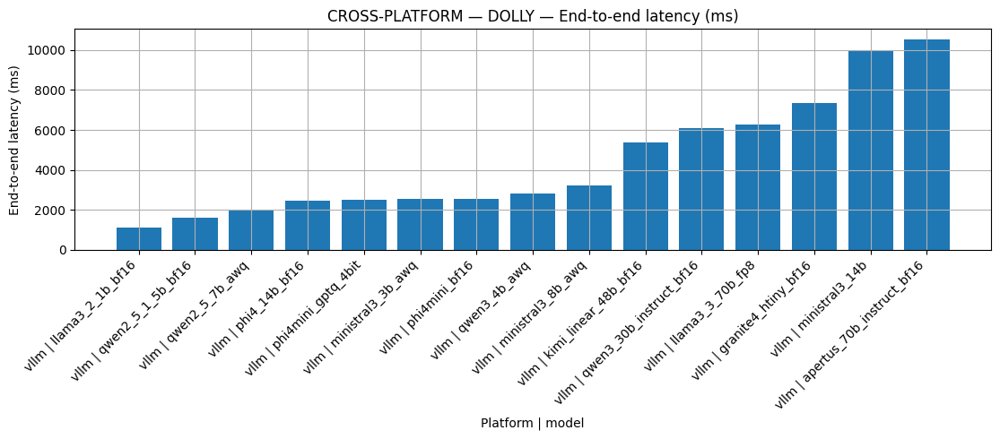

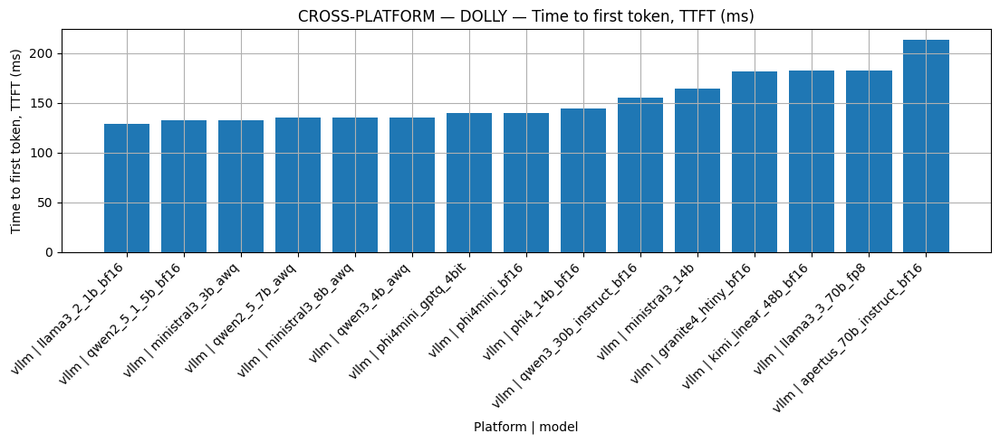

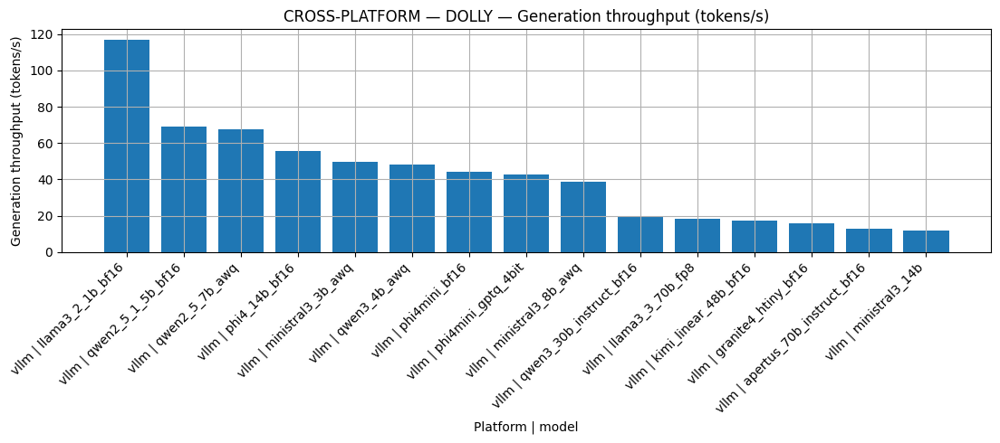

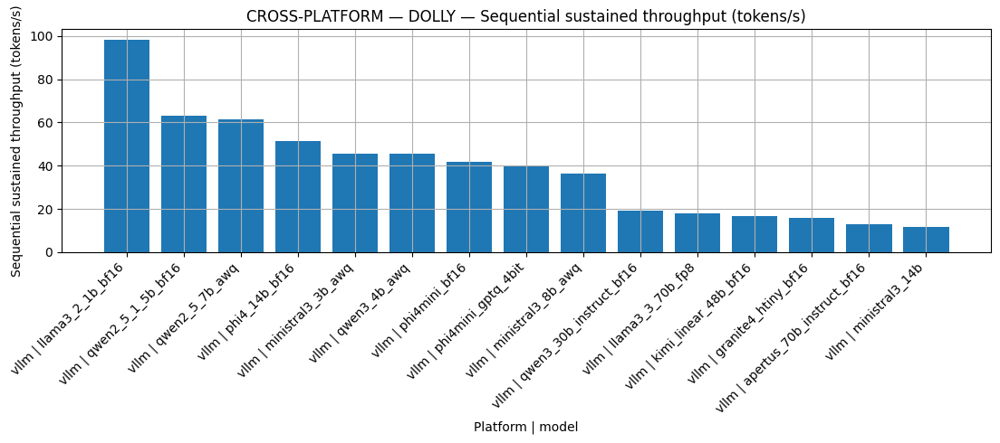

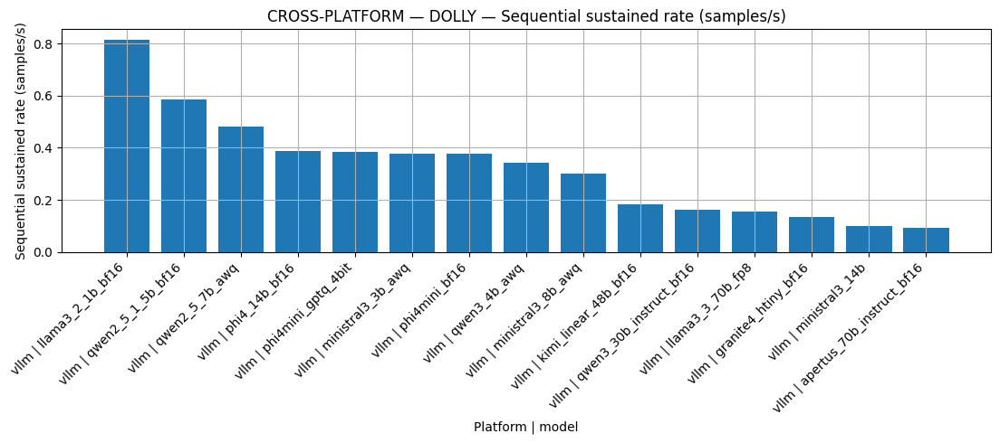

...

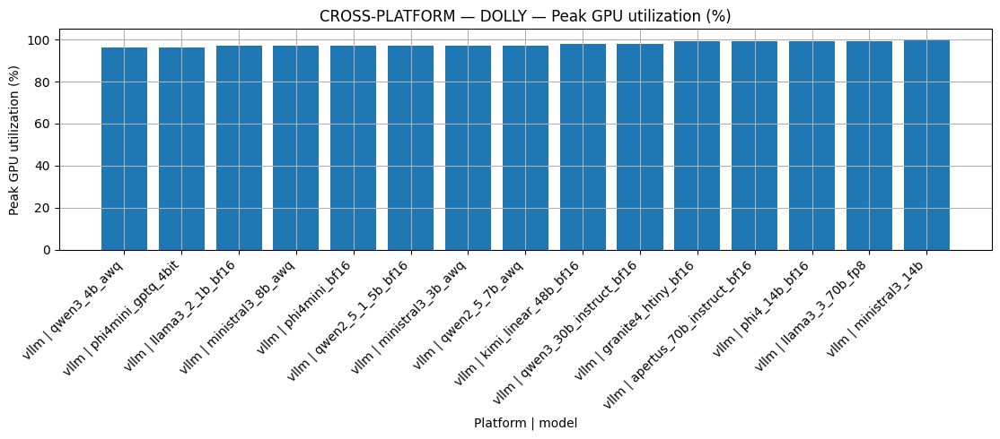

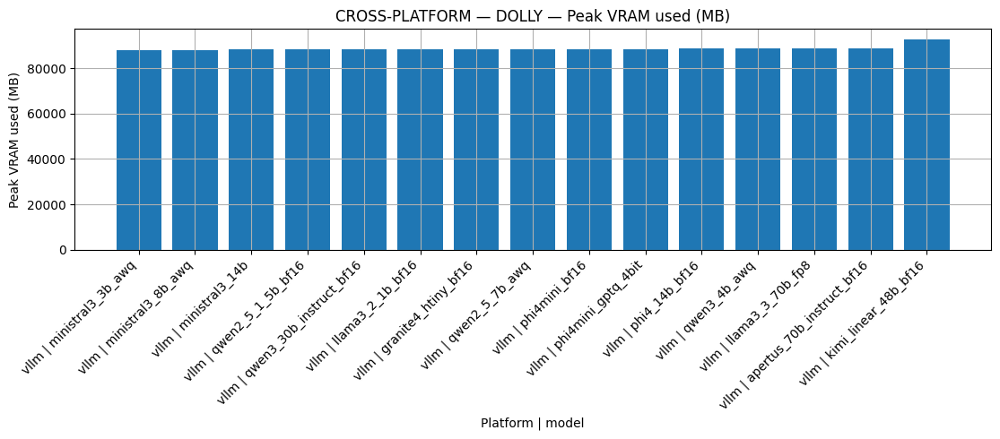

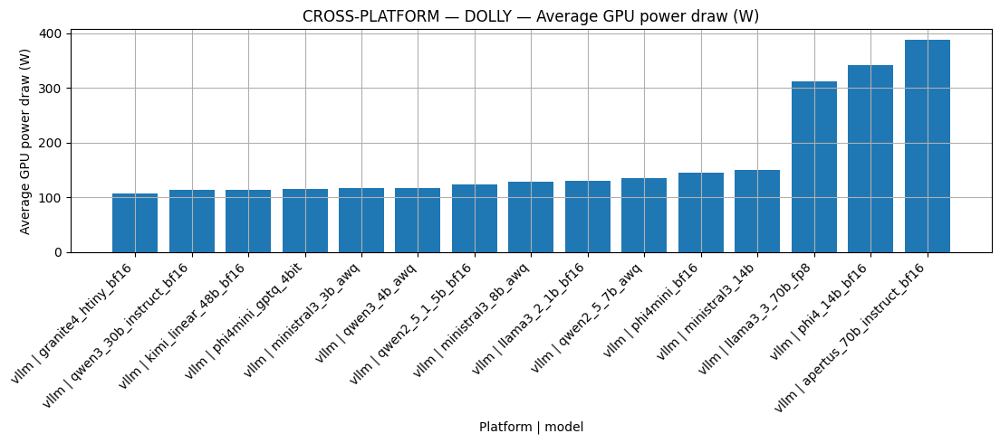

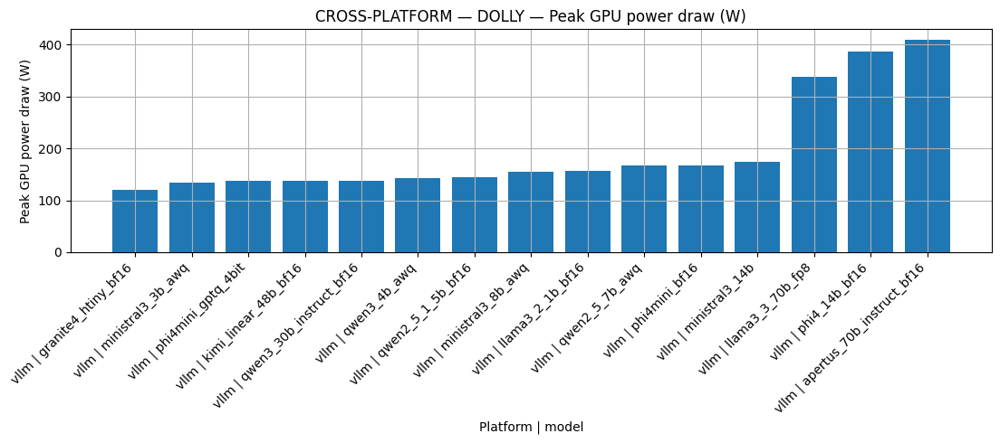

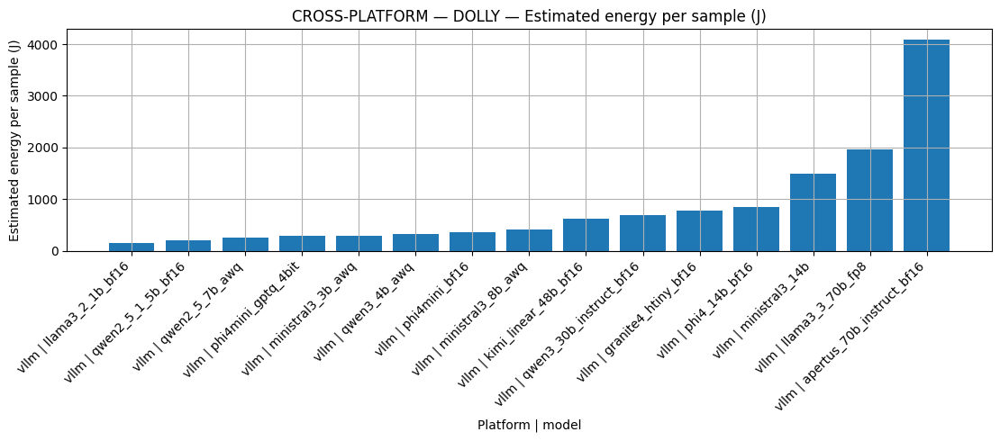

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


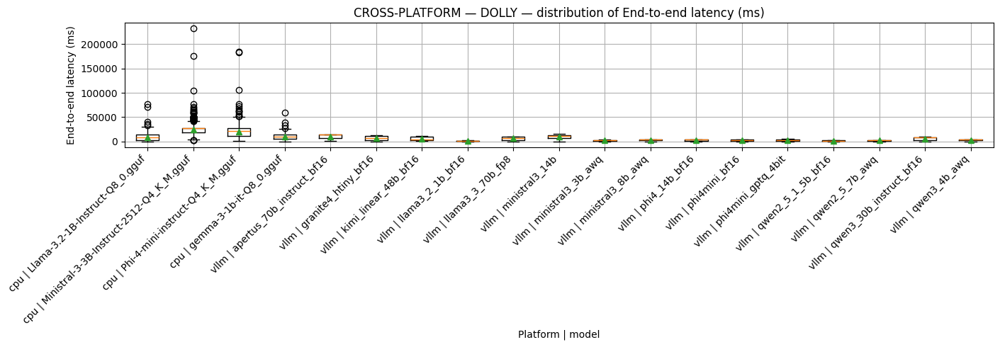

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


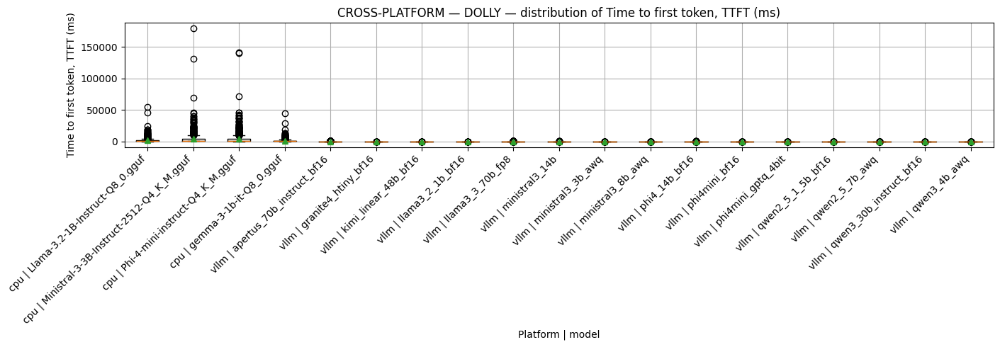

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


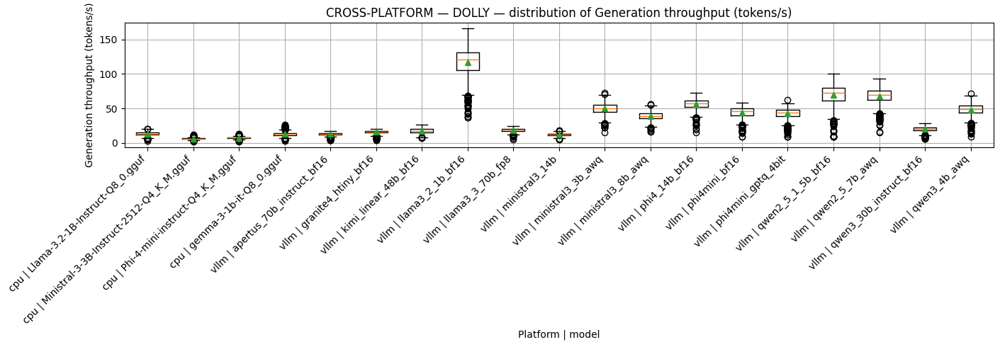

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


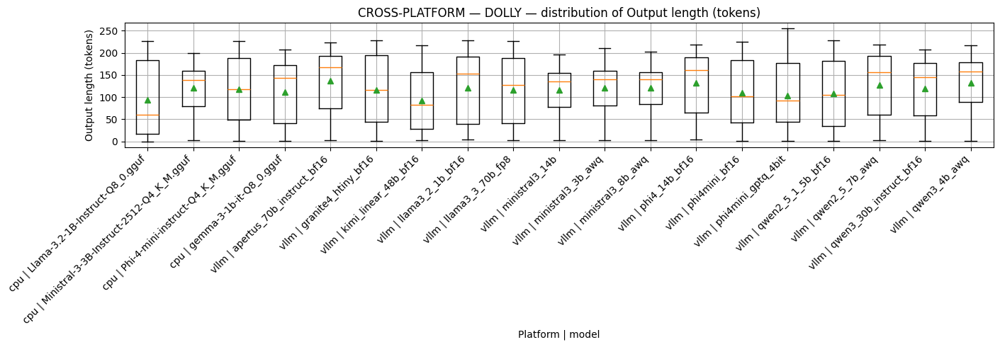

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


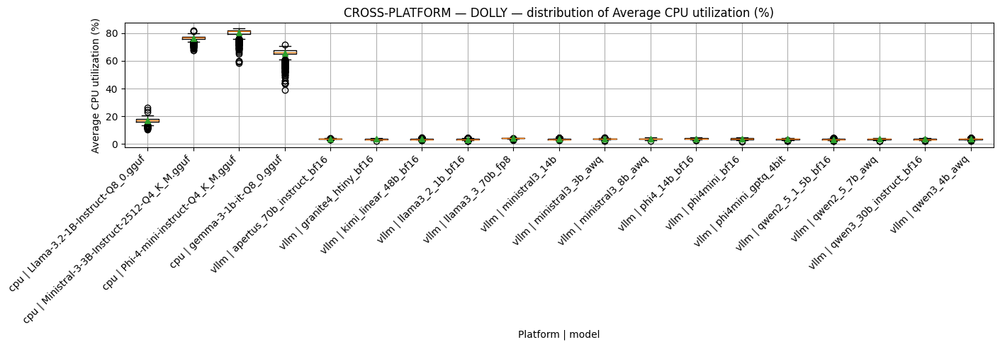

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


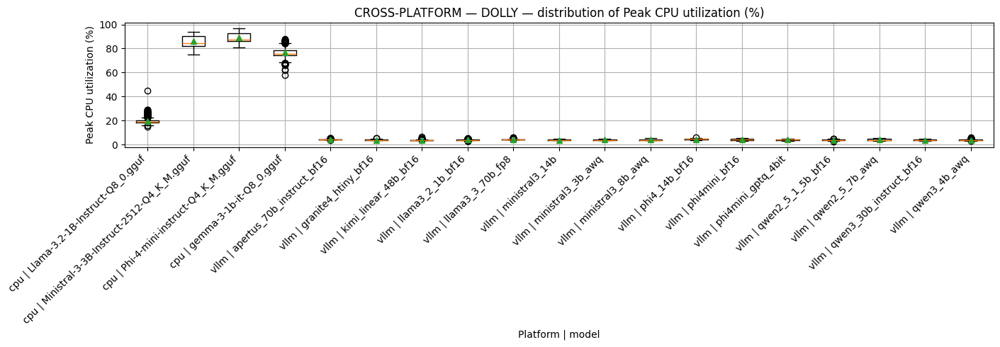

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


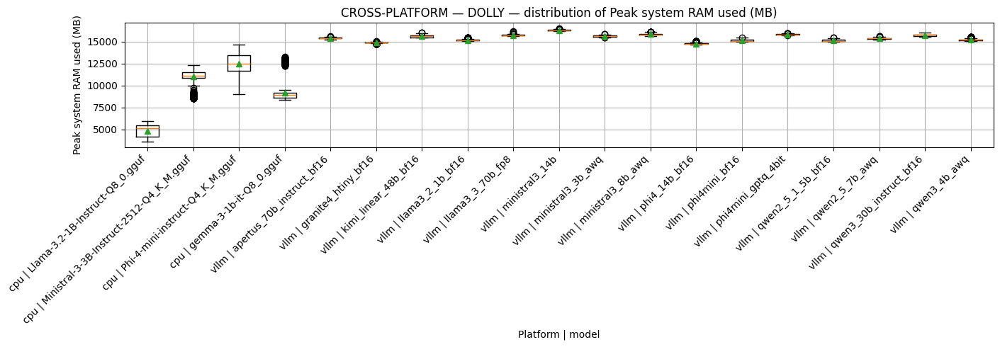

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


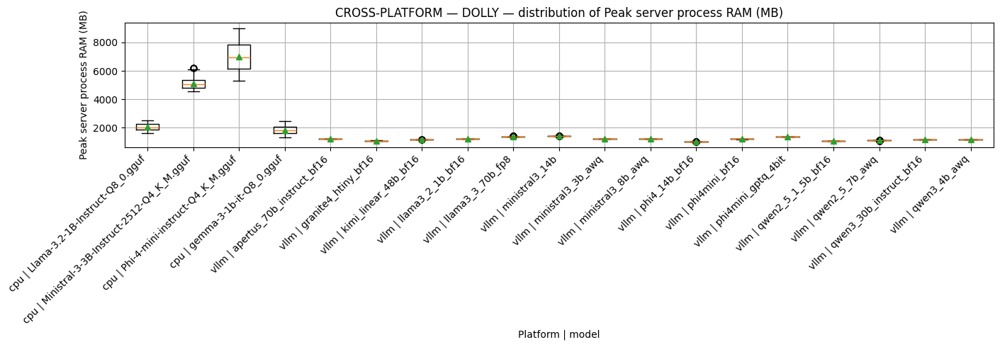

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


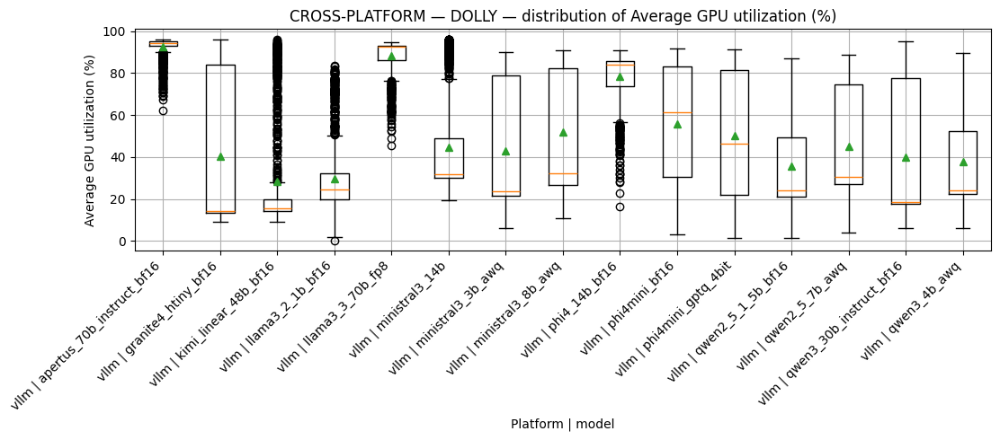

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


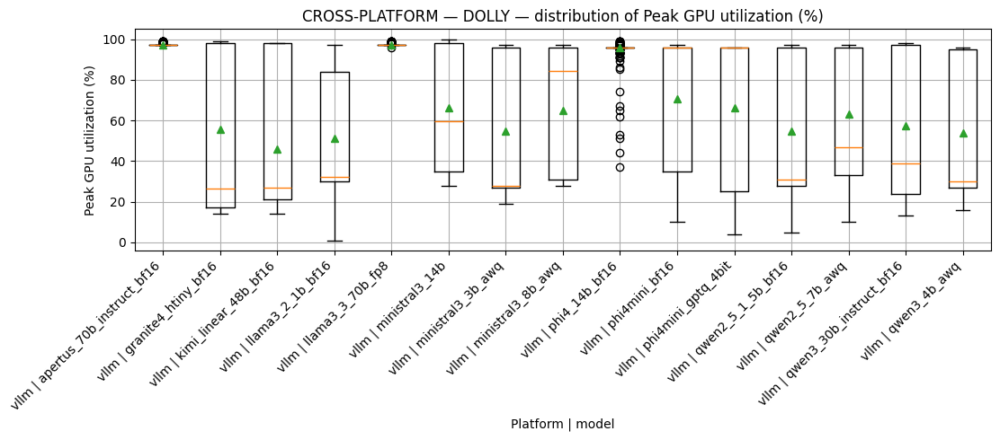

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


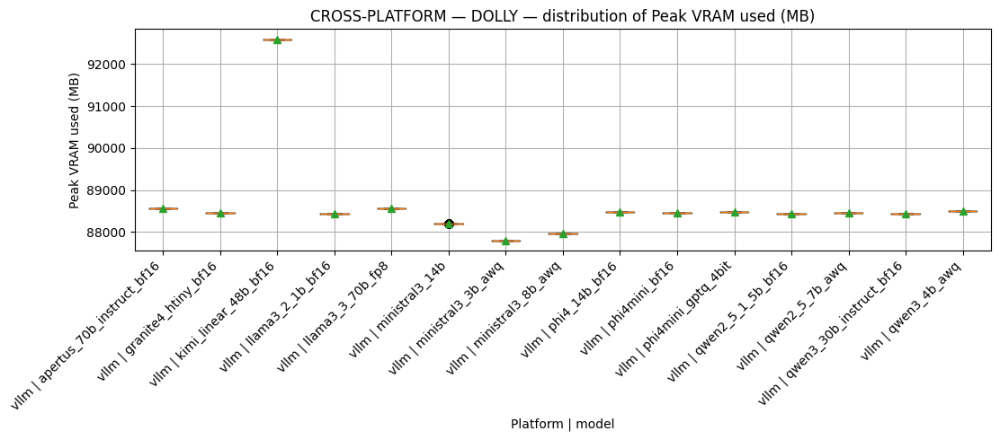

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


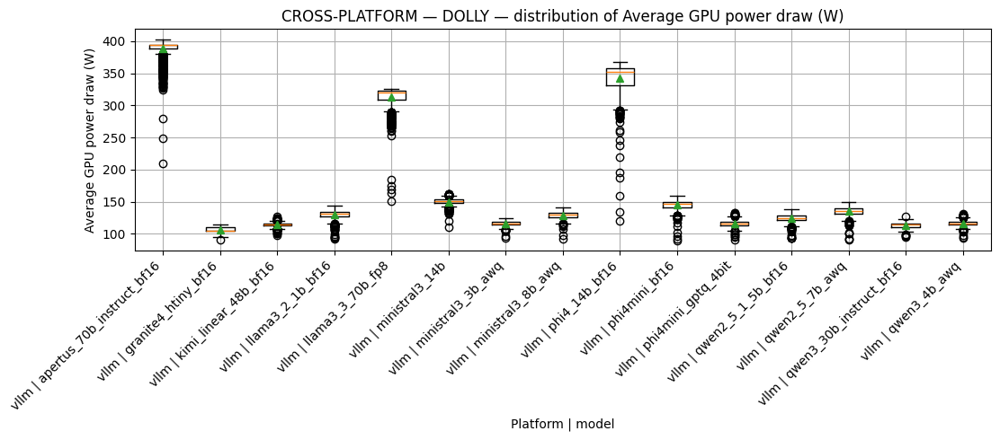

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


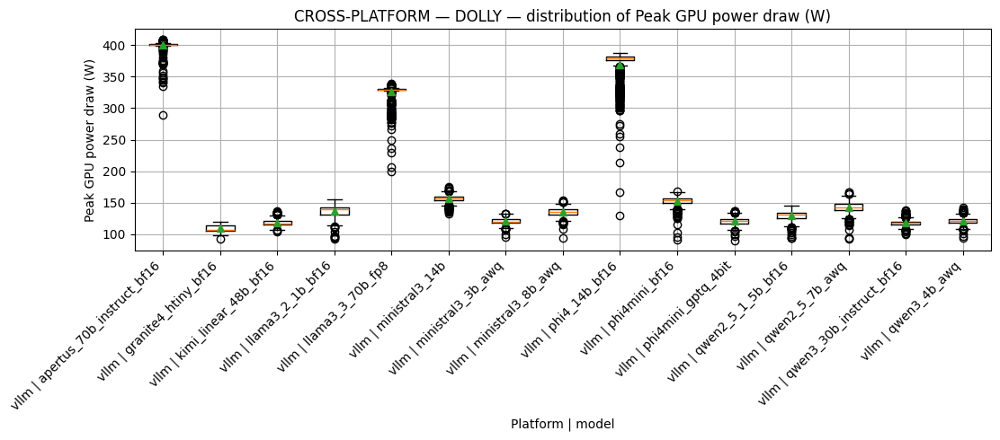

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


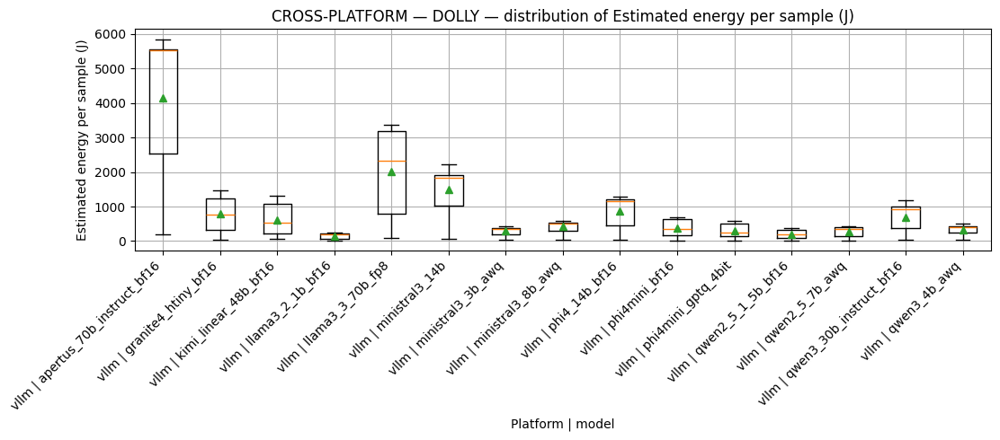

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


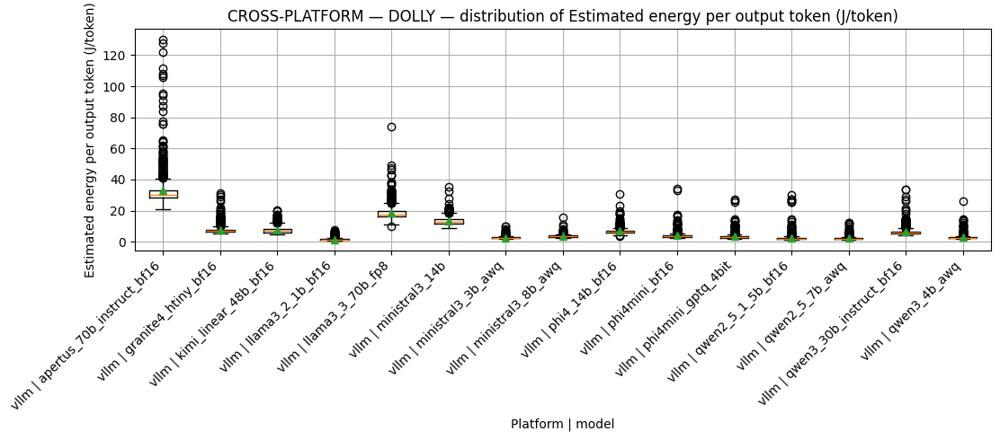

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


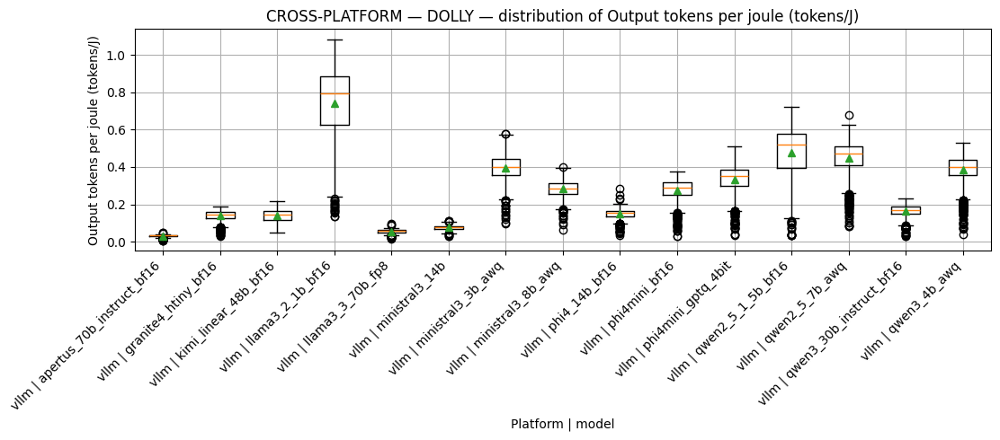

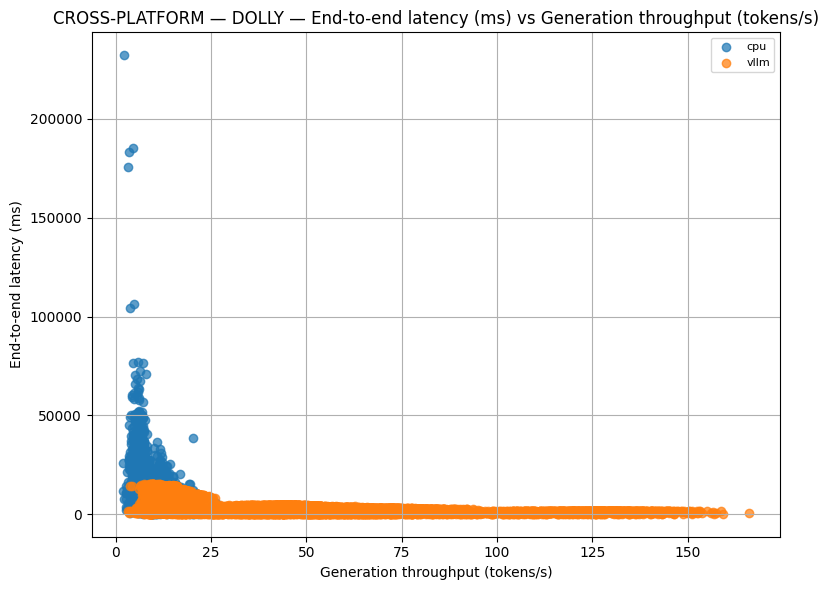

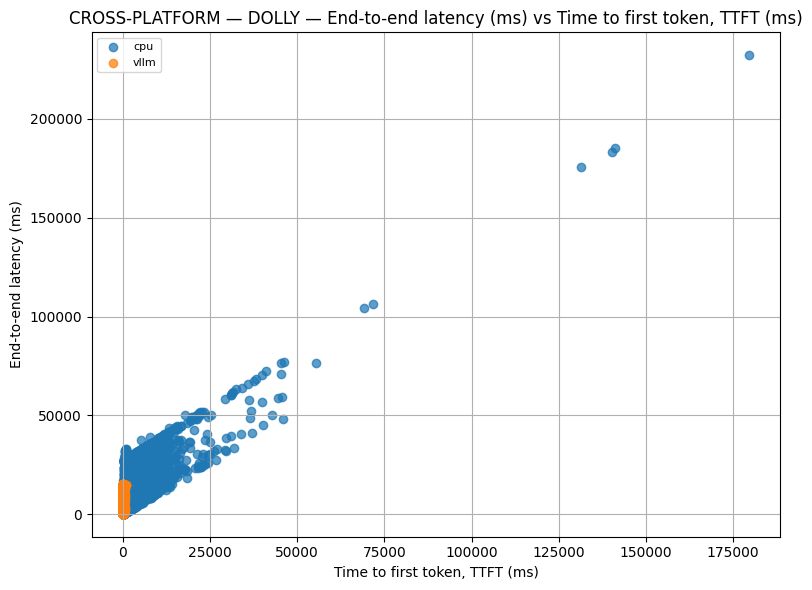

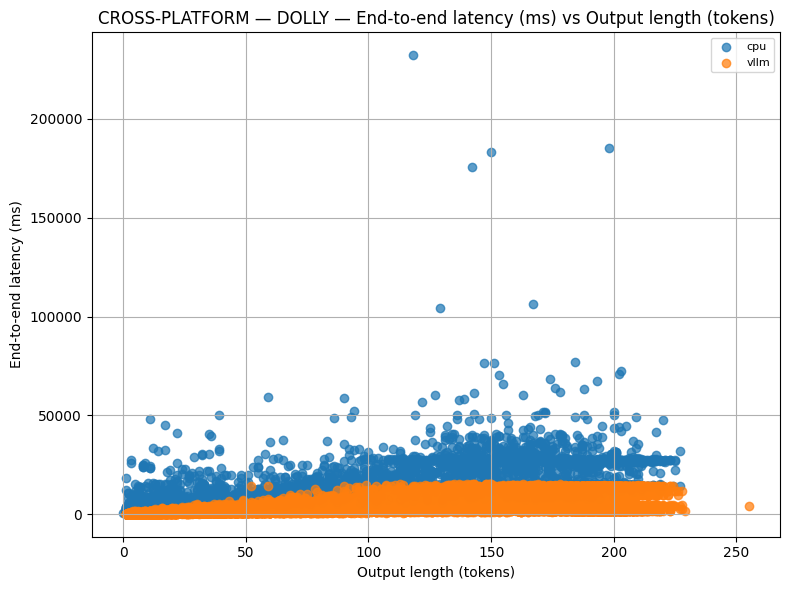

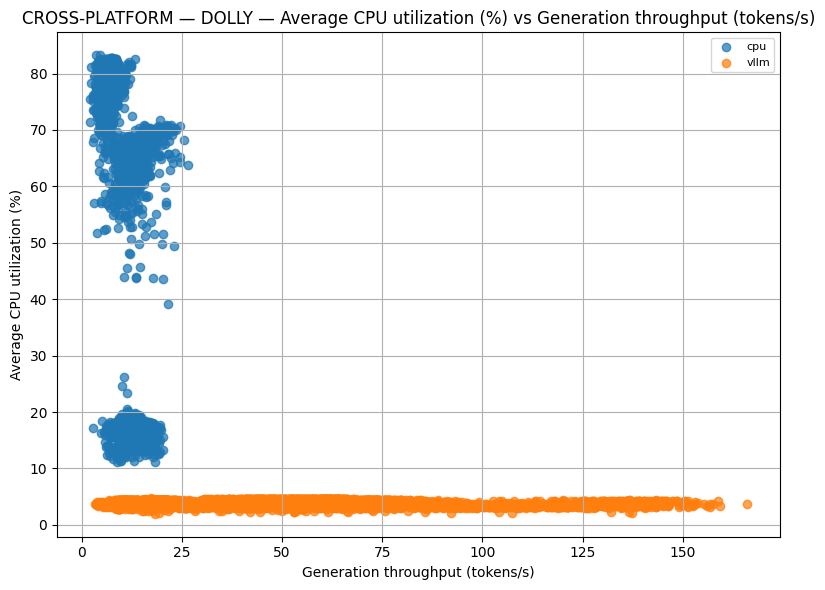

...

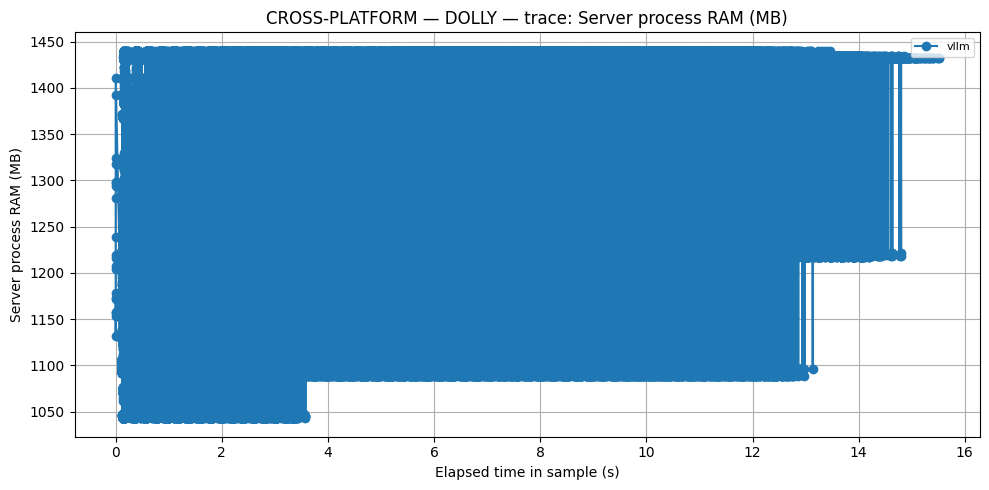

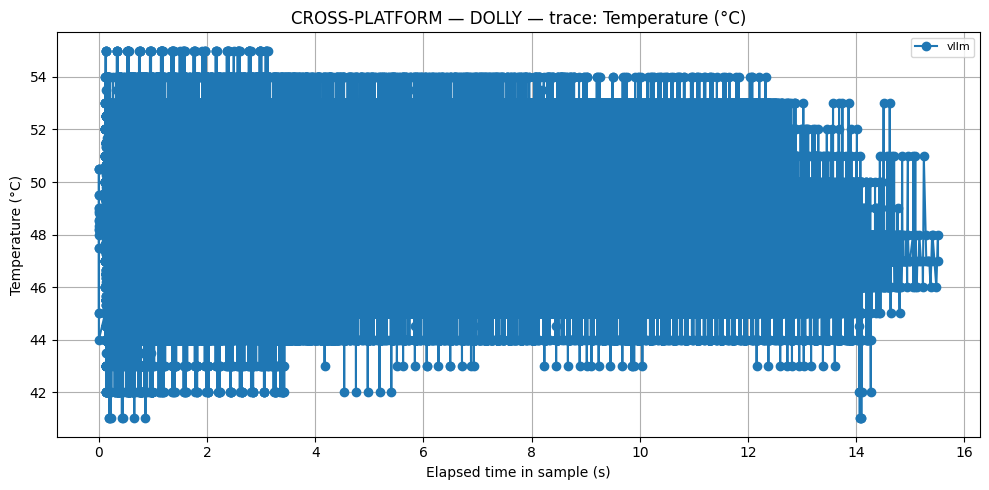

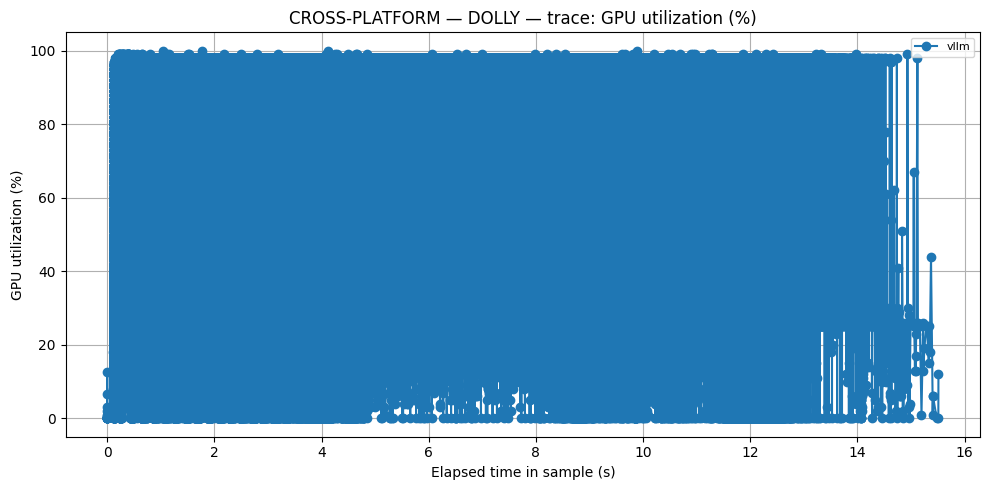

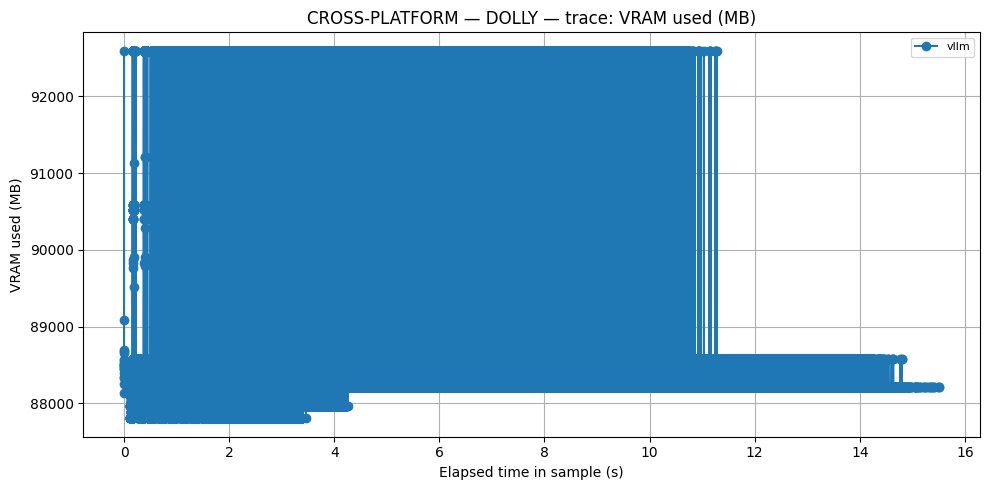

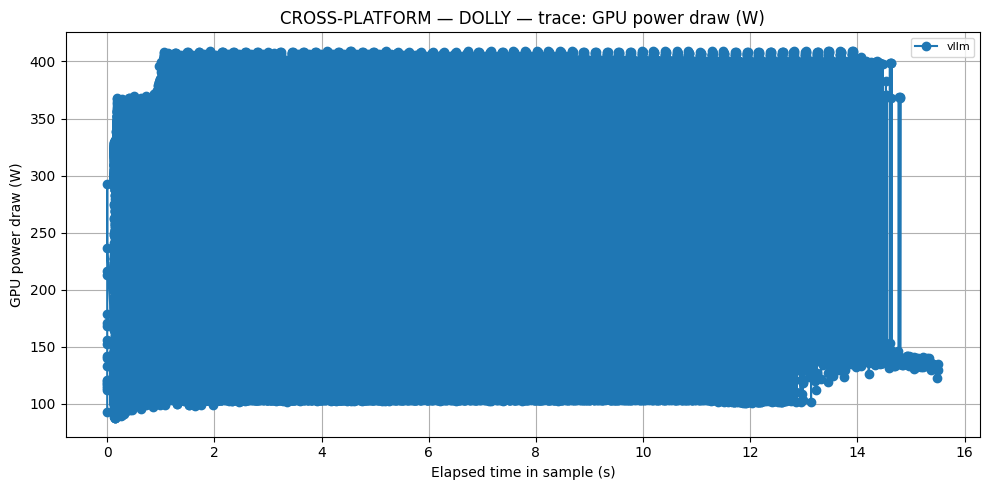


=== CROSS-PLATFORM / GSM8K ===


,platform,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,gpu_util_percent_avg,gpu_util_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,energy_j,accuracy_per_second,accuracy_per_joule
8,vllm,llama3_3_70b_fp8,0.7450,7057.81200,167.89960,20.94670,20.13545,0.14075,4.26980,6.30,15808.615,1318.235,91.60055,97.5,88565.0,318.8202,336.955,2251.372828,0.106477,0.000334
6,vllm,kimi_linear_48b_bf16,0.7100,5874.96770,184.69800,15.41110,14.97120,0.16740,3.68100,5.60,15733.230,1172.120,33.14760,98.0,92591.0,114.2148,132.600,671.008261,0.120852,0.001058
5,vllm,granite4_htiny_bf16,0.6900,7333.12765,184.69670,14.92215,14.29180,0.13450,3.66585,5.40,15285.260,1098.790,43.34595,98.0,88449.0,107.1771,117.705,785.942321,0.094094,0.000878
13,vllm,phi4mini_bf16,0.6700,2917.93030,136.32850,42.98810,38.89030,0.33040,3.91810,5.50,15377.840,1211.570,59.39870,96.0,88465.0,149.3435,173.960,435.773924,0.229615,0.001537
2,cpu,Phi-4-mini-instruct-Q4_K_M.gguf,0.6400,18628.56810,2412.32155,7.44045,6.32060,0.05390,81.30885,94.35,12601.380,8120.295,NaN,NaN,NaN,NaN,NaN,NaN,0.034538,NaN
14,vllm,phi4mini_gptq_4bit,0.6100,2995.84130,138.47790,41.15870,37.50410,0.32210,3.86240,5.80,15974.870,1372.780,56.70940,97.0,88477.0,117.7534,137.360,352.770499,0.203616,0.001729
4,vllm,apertus_70b_instruct_bf16,0.6010,10968.86440,198.12290,12.03360,11.67370,0.09020,4.04660,5.70,15664.230,1220.130,94.44220,98.0,88569.0,393.2261,404.940,4313.243769,0.054791,0.000139
9,vllm,ministral3_14b,0.5900,11526.80540,157.69560,10.72220,10.49270,0.08590,3.77240,5.80,16445.640,1433.010,50.60680,100.0,88211.0,151.5702,168.400,1747.120200,0.051185,0.000338
17,vllm,qwen3_30b_instruct_bf16,0.5900,6934.77220,152.47810,16.59690,16.02700,0.14210,3.79110,5.30,15937.450,1168.500,43.90340,98.0,88445.0,113.8954,134.760,789.838654,0.085078,0.000747
16,vllm,qwen2_5_7b_awq,0.5500,2465.00140,131.65490,59.22450,53.37240,0.38860,3.72200,6.90,16132.960,1107.020,41.10040,97.0,88459.0,136.9315,155.770,337.536339,0.223124,0.001629


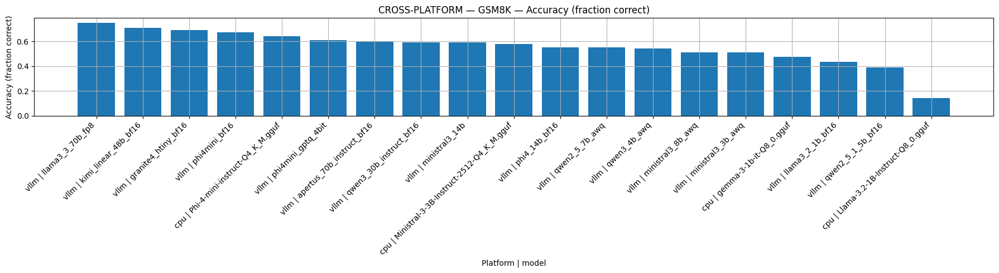

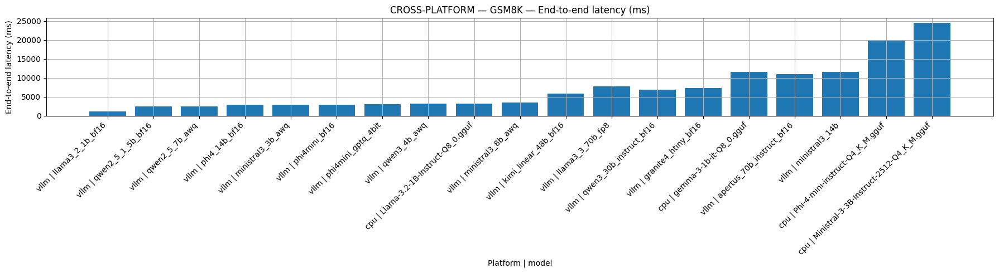

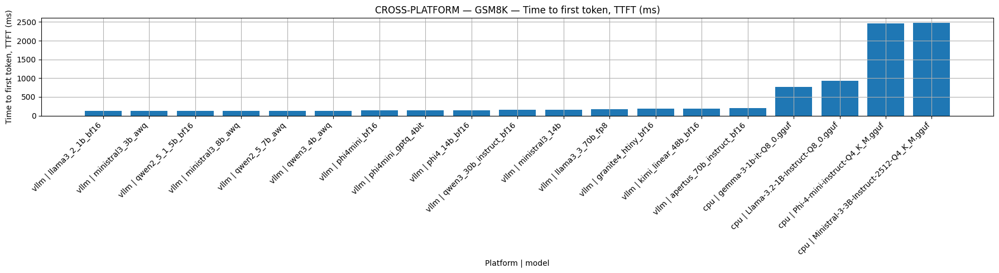

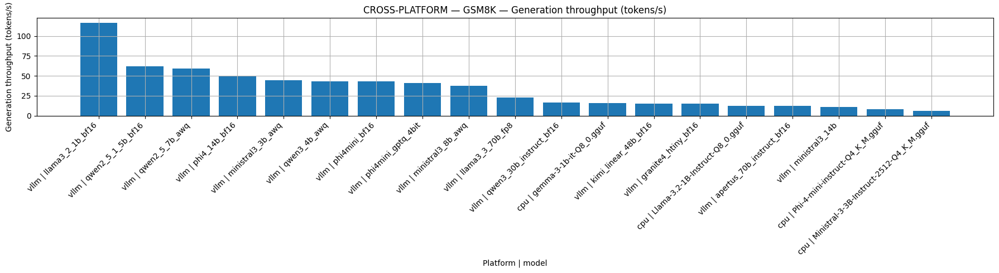

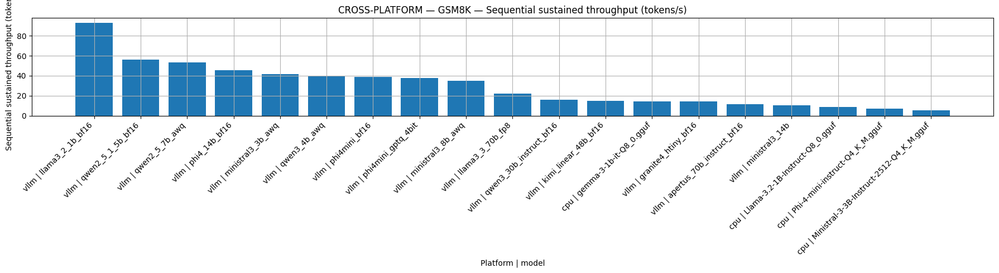

...

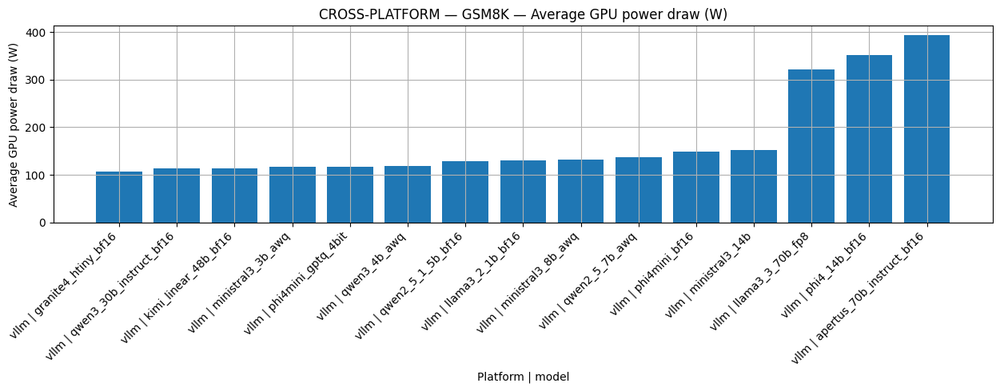

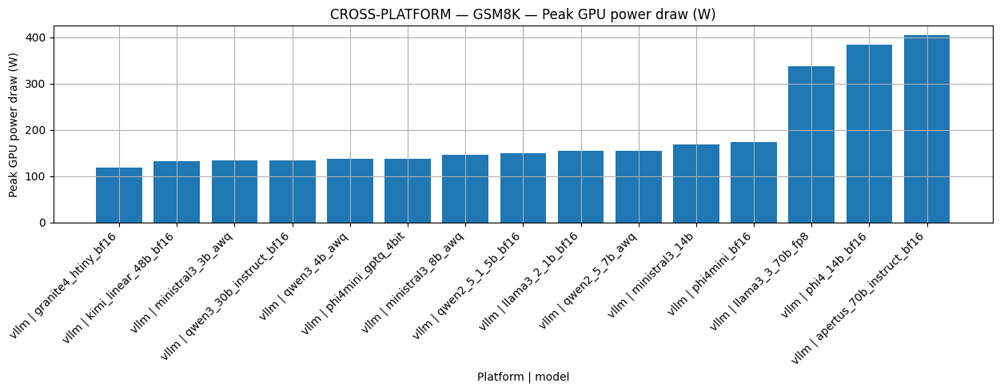

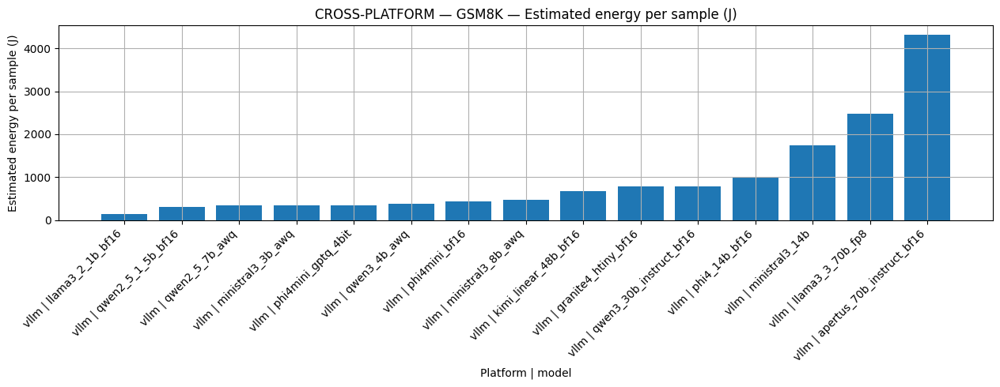

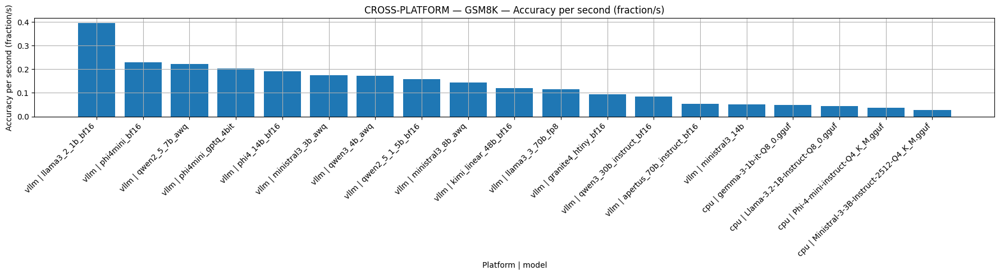

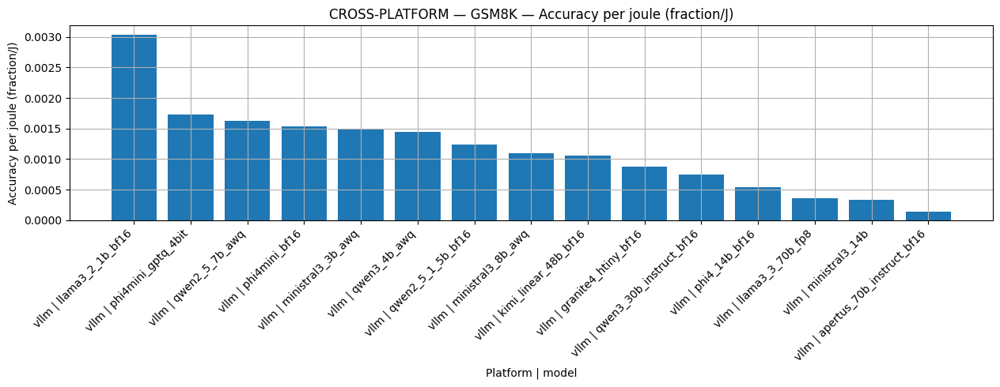

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


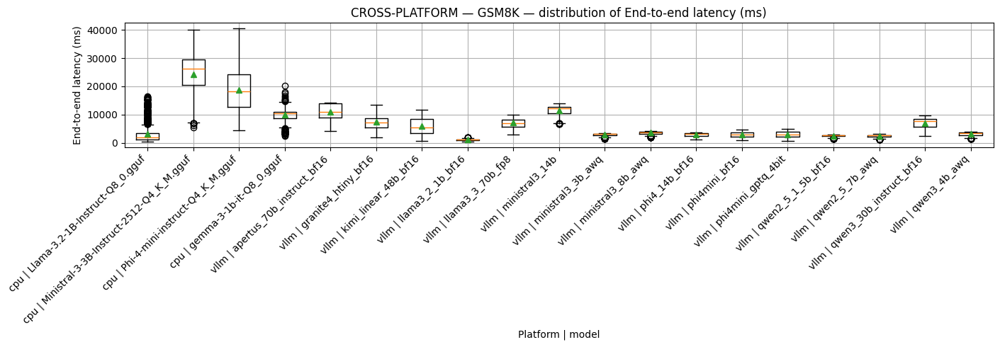

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


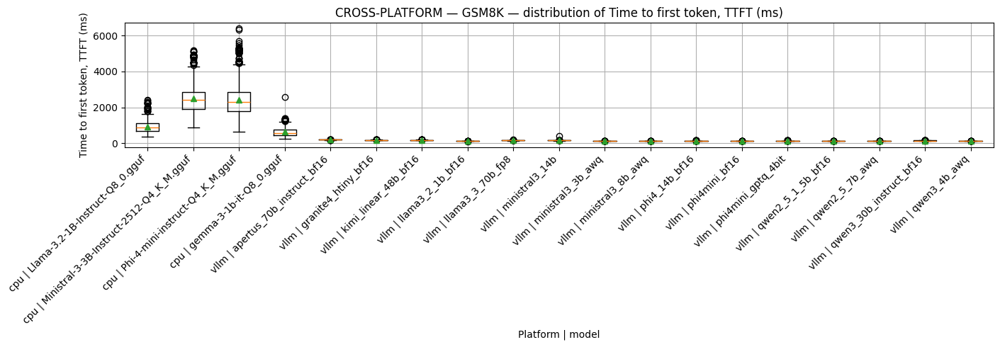

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


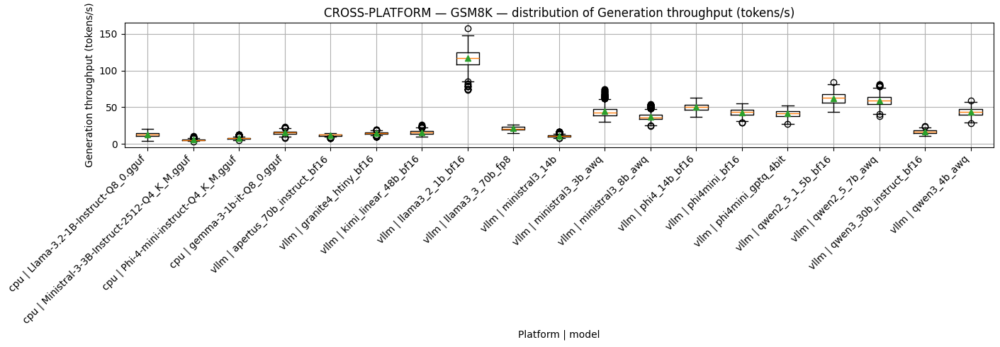

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


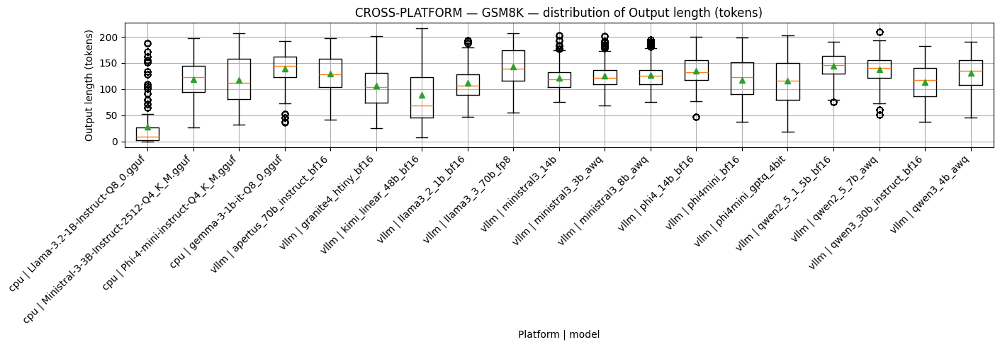

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


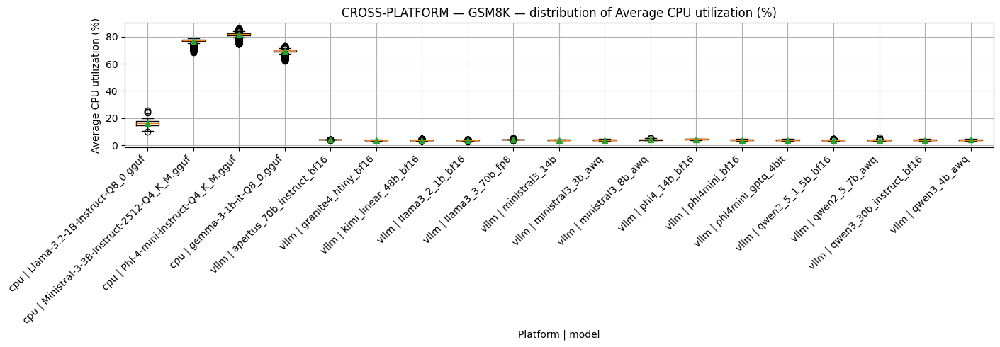

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


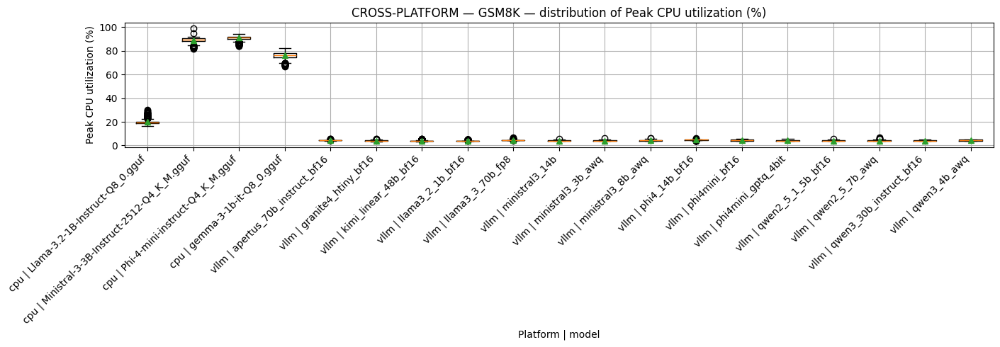

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


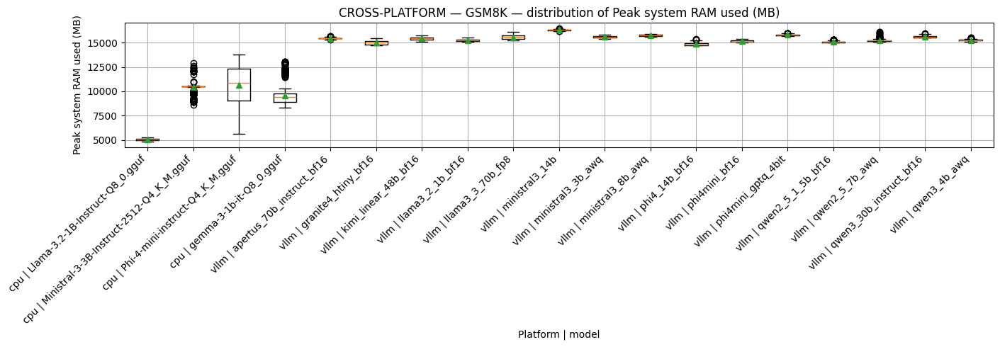

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


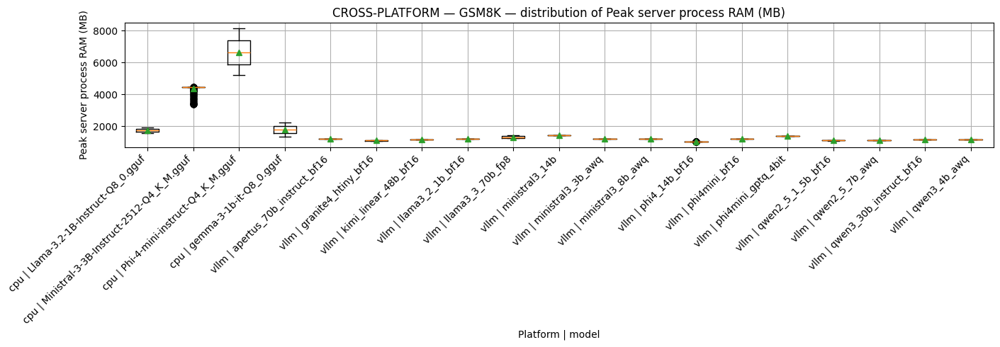

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


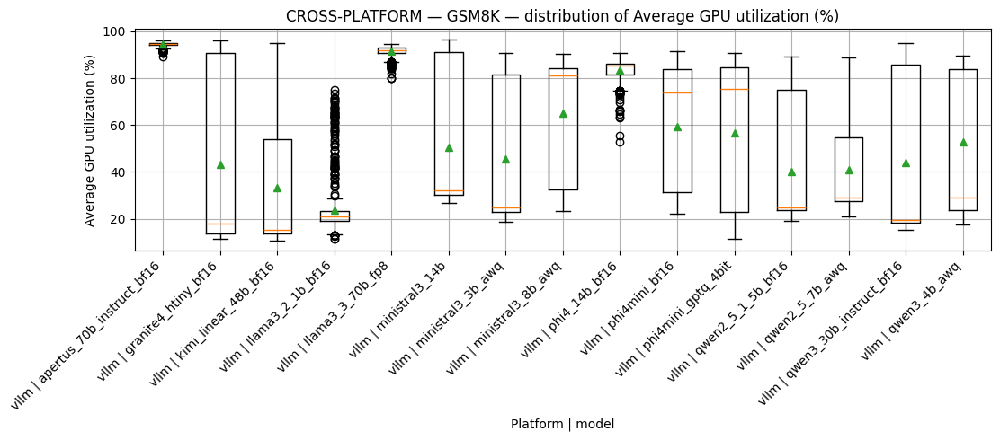

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


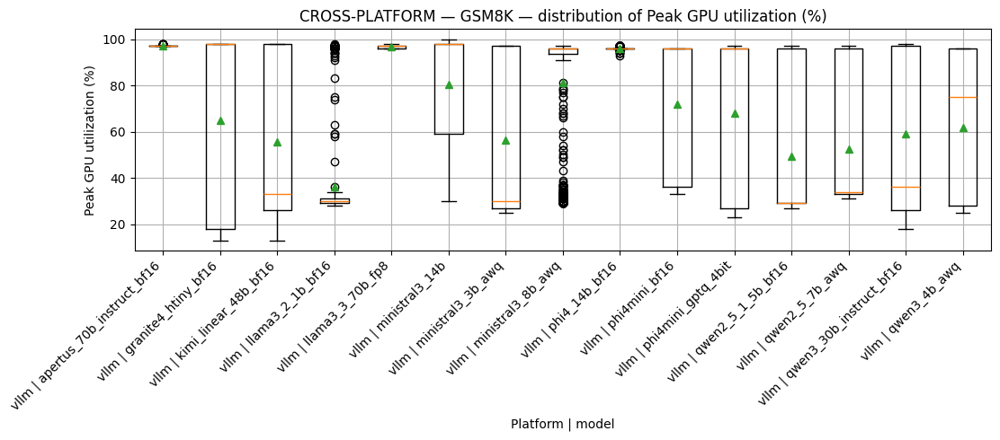

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


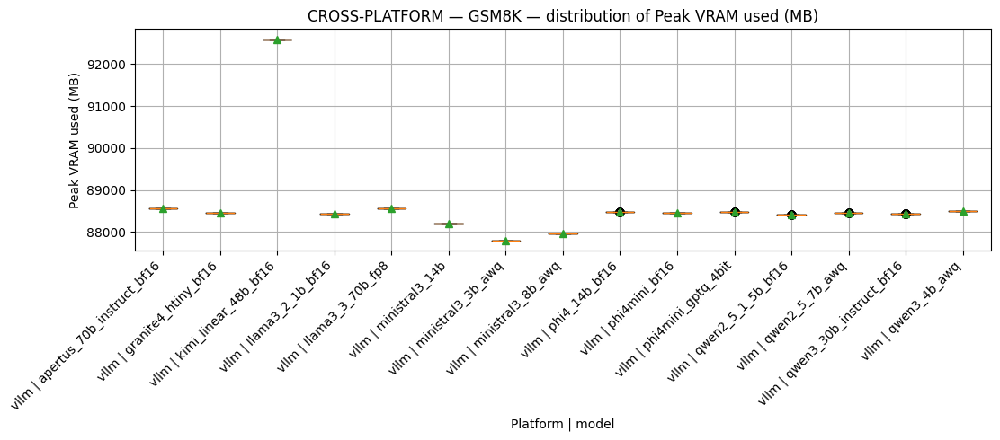

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


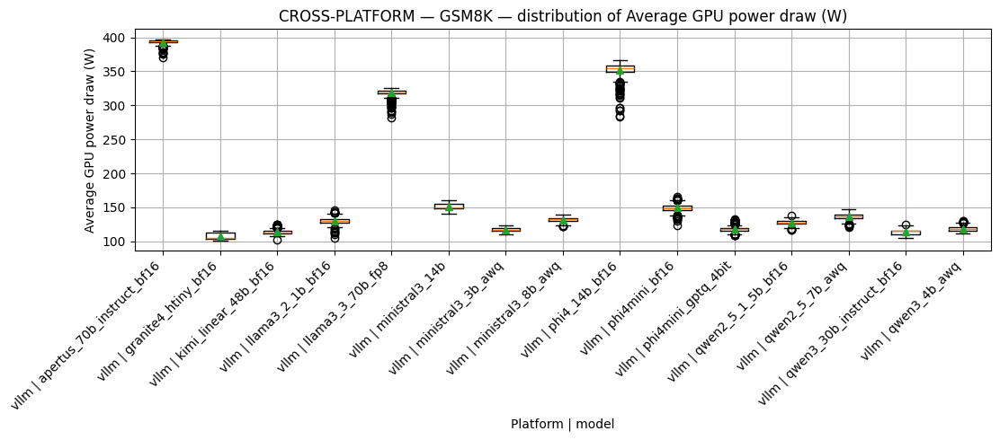

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


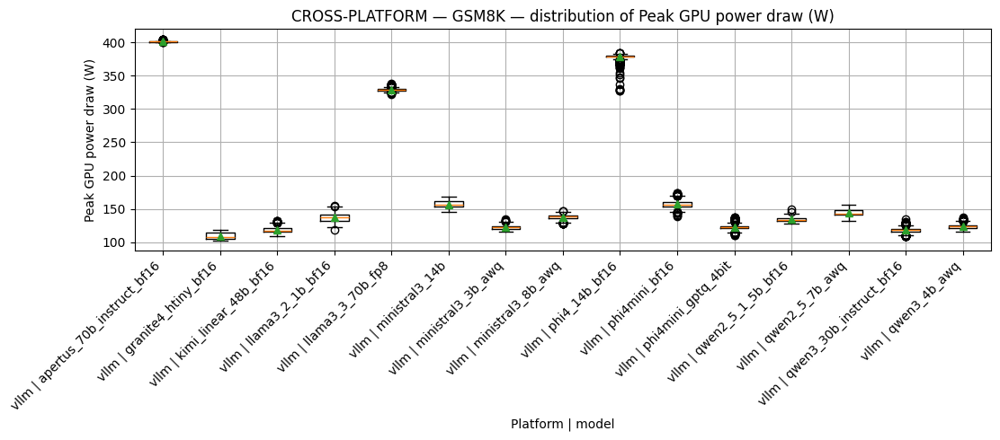

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


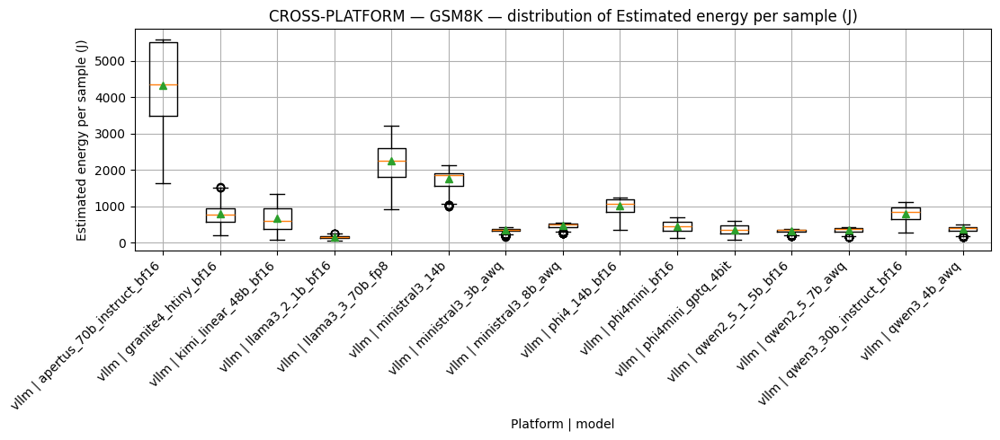

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


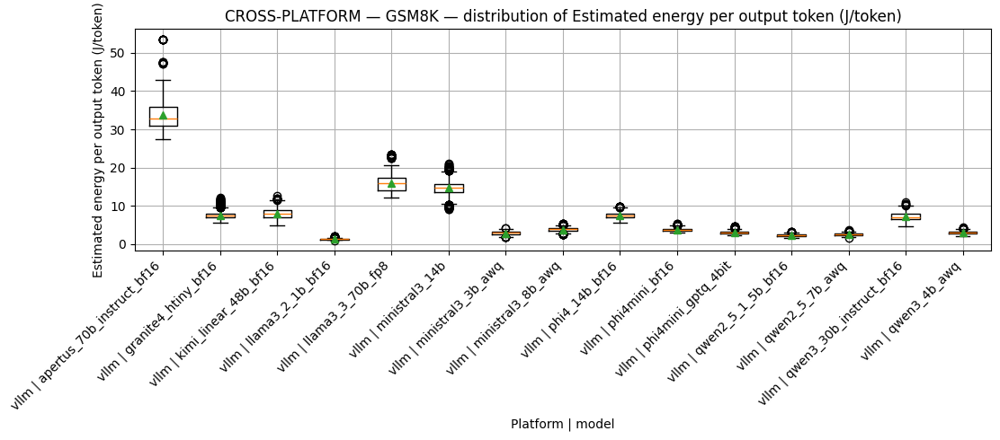

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


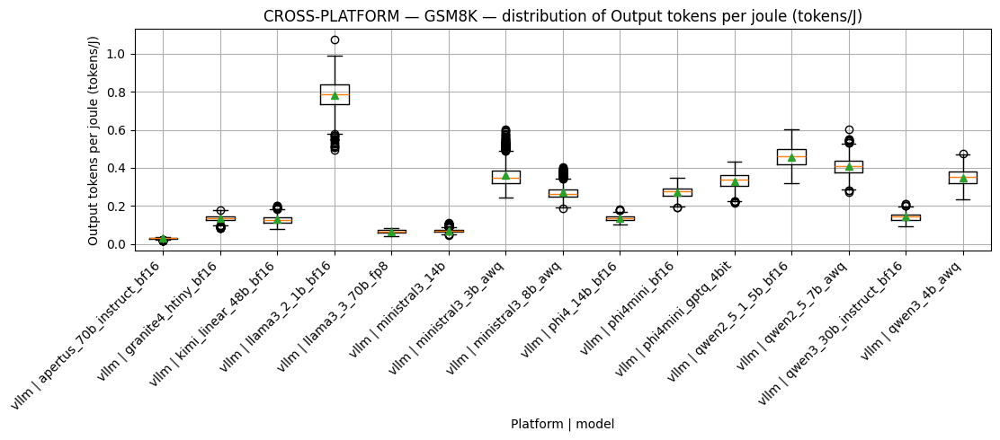

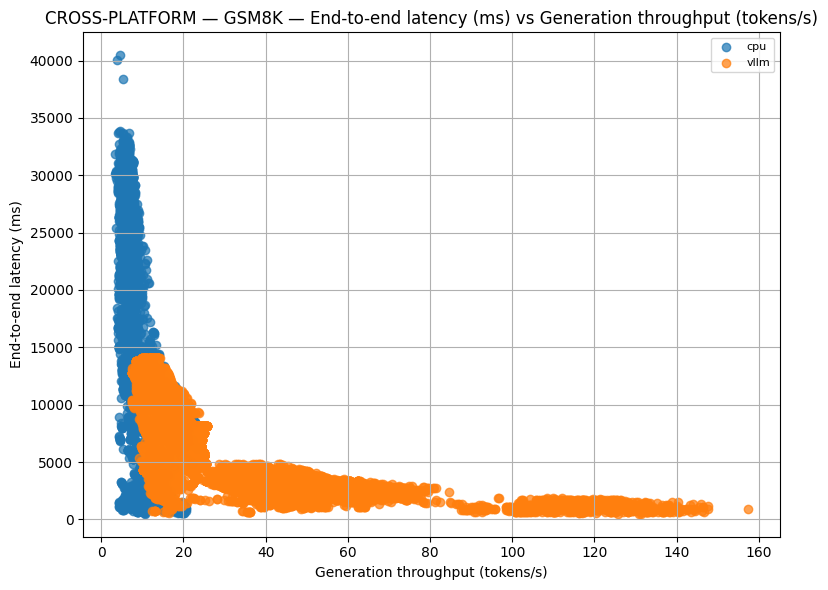

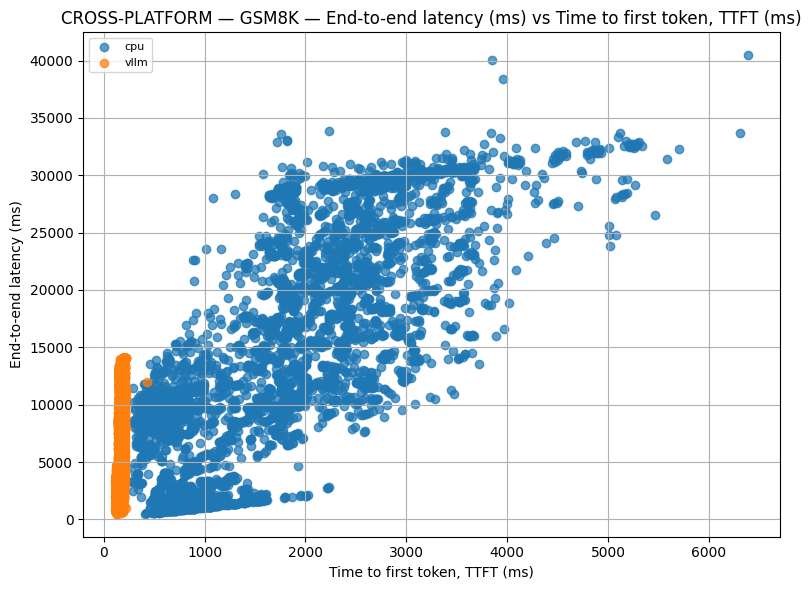

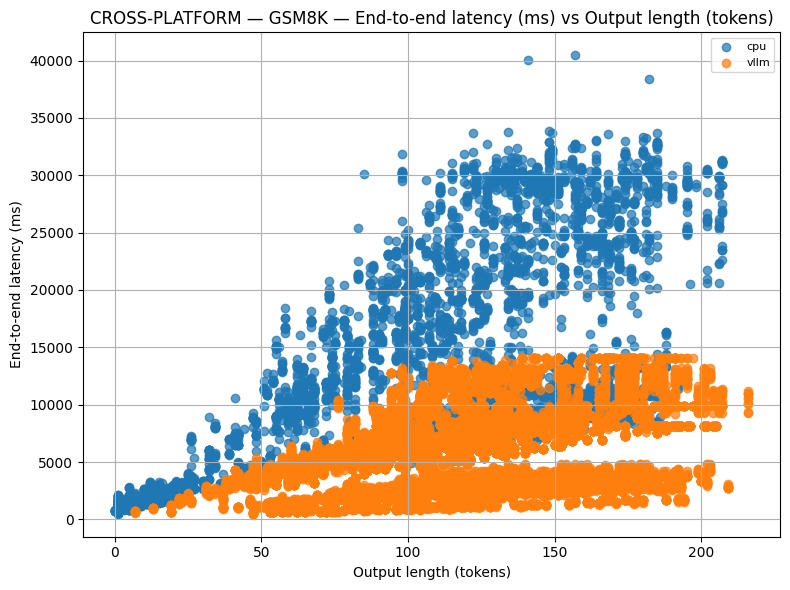

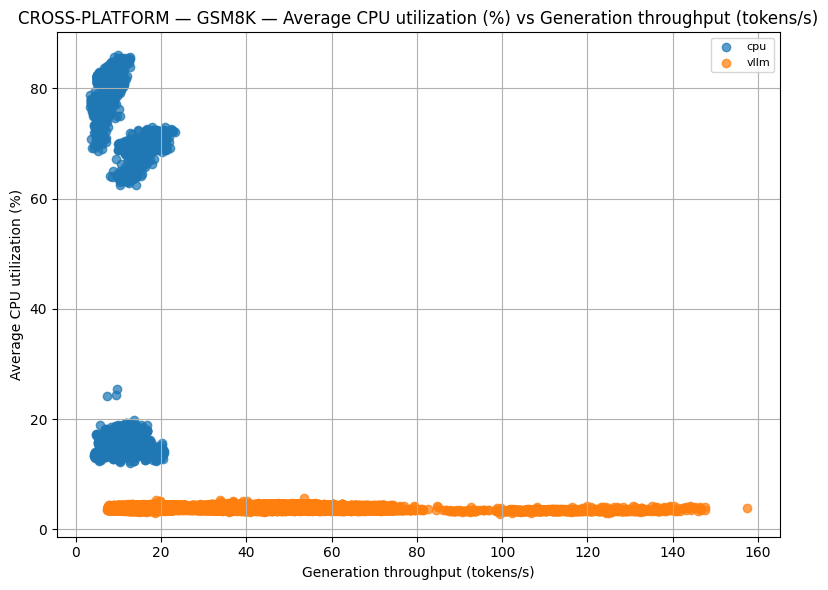

...

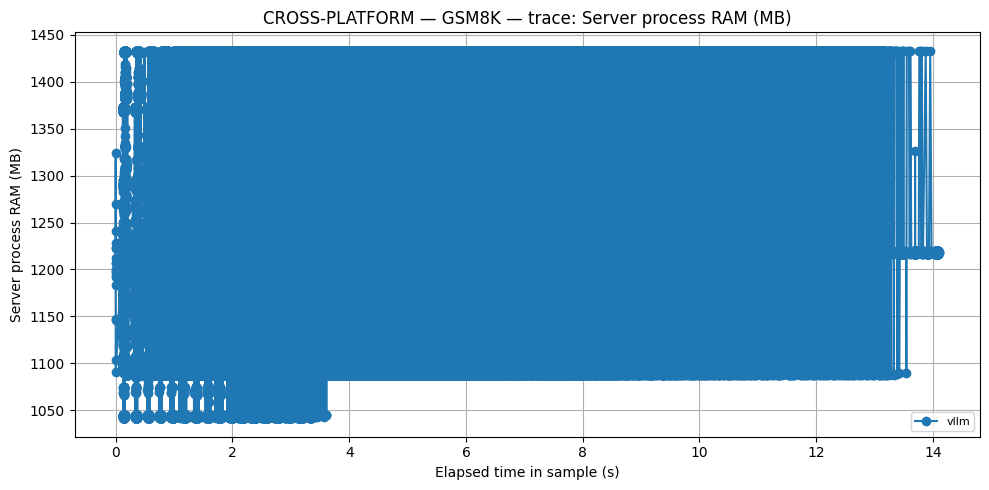

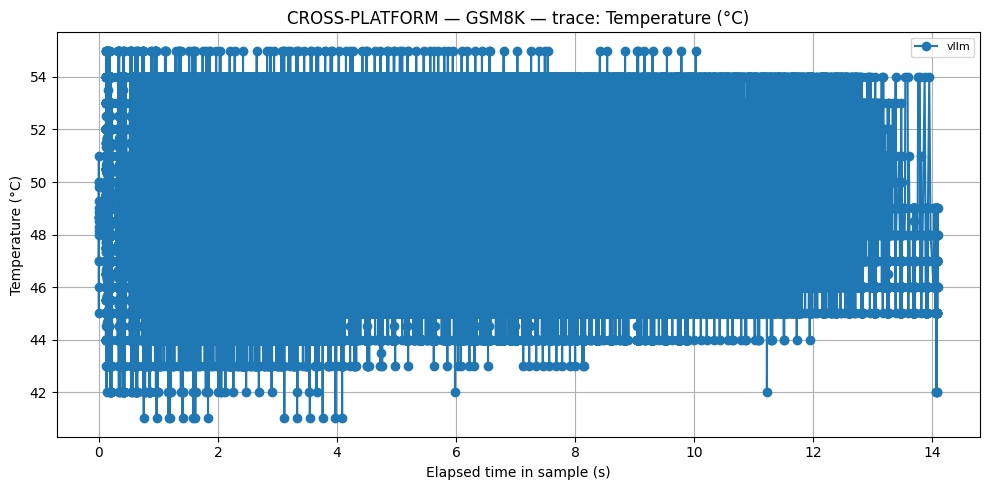

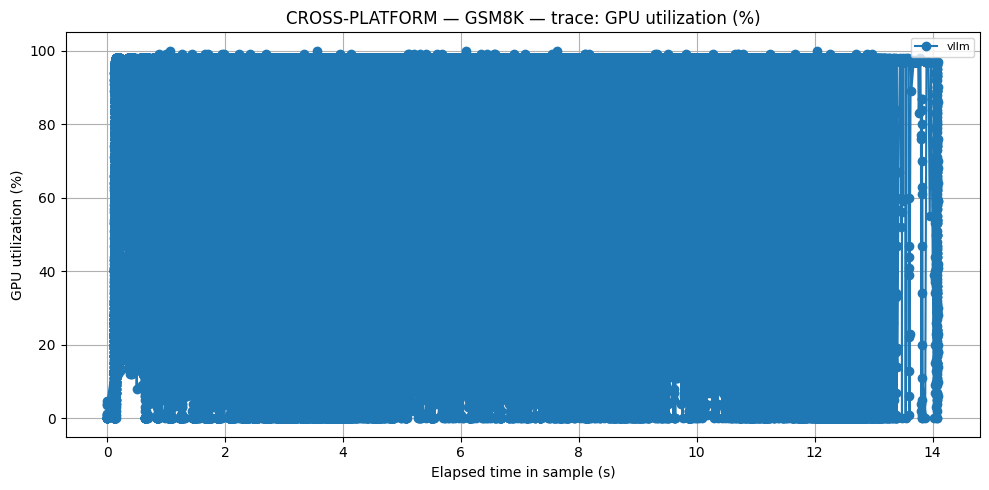

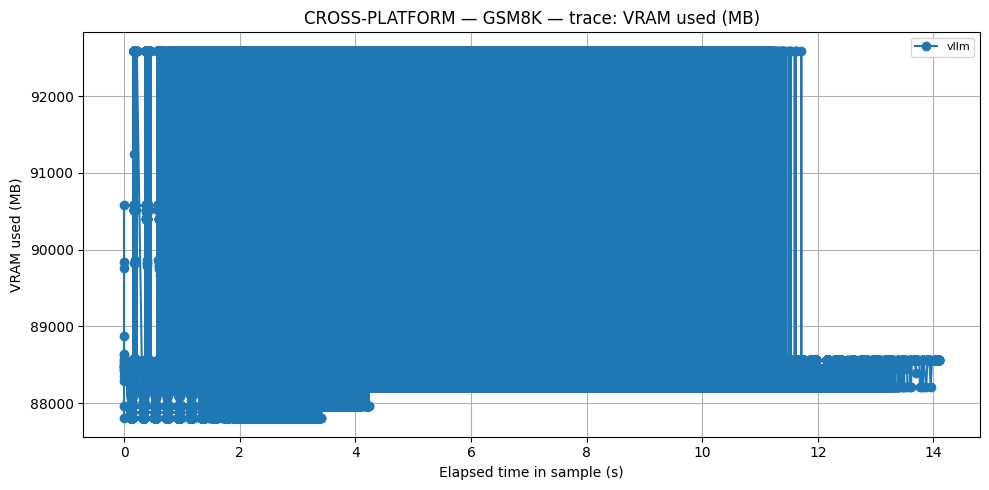

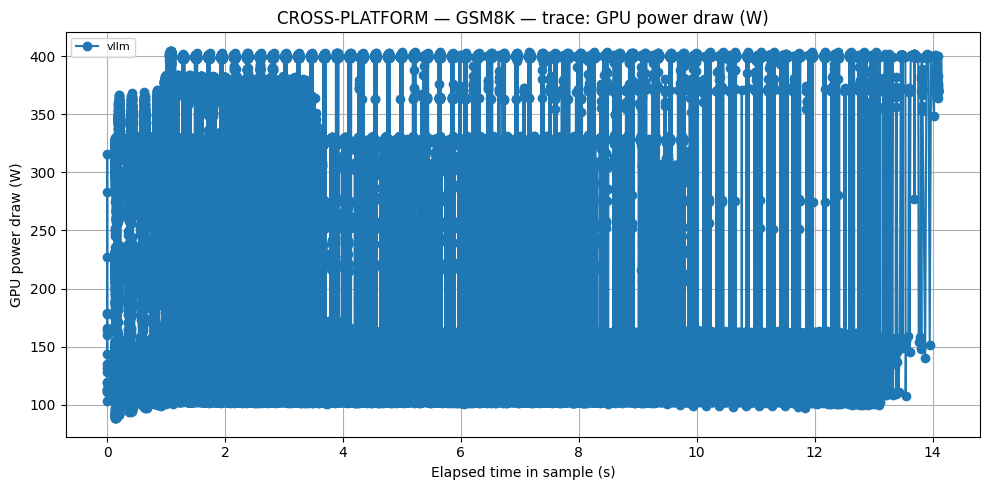


=== CROSS-PLATFORM / HELLASWAG ===


,platform,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,gpu_util_percent_avg,gpu_util_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,energy_j,accuracy_per_second,accuracy_per_joule
12,vllm,phi4_14b_bf16,0.850,263.43020,149.67670,9.84710,2.99140,2.67090,2.95250,3.80,15545.350,1047.900,15.2993,97.0,88487.0,131.1703,178.480,34.554218,3.226661,0.024599
8,vllm,llama3_3_70b_fp8,0.835,306.17655,190.48390,8.65655,2.40640,2.40640,3.19050,4.30,15926.195,1315.890,34.3908,98.0,88561.0,173.1794,237.540,53.039413,2.727576,0.015774
17,vllm,qwen3_30b_instruct_bf16,0.790,264.48070,151.33640,8.85090,2.66970,2.66970,2.94960,3.90,16107.180,1169.320,19.7040,98.0,88447.0,110.8229,137.640,29.310518,2.986985,0.026953
18,vllm,qwen3_4b_awq,0.690,250.24700,137.32020,8.87020,2.76600,2.76600,2.87220,4.40,15733.050,1174.140,7.7753,92.0,88503.0,97.4275,111.440,24.380940,2.757276,0.028301
11,vllm,ministral3_8b_awq,0.640,249.24640,136.68980,8.89940,2.77550,2.77550,2.90350,4.00,16454.410,1210.800,8.4670,96.0,87963.0,102.3364,122.840,25.506979,2.567740,0.025091
5,vllm,granite4_htiny_bf16,0.640,297.00505,176.39130,9.04350,2.72590,2.45580,3.10445,4.35,15311.080,1098.585,21.6205,98.0,88453.0,100.5196,113.355,29.854843,2.154853,0.021437
16,vllm,qwen2_5_7b_awq,0.590,248.24880,136.57010,8.97060,2.79250,2.79250,2.82100,4.60,15623.750,1106.120,6.3900,90.0,88459.0,100.7551,123.850,25.012333,2.376648,0.023588
9,vllm,ministral3_14b,0.570,274.66290,157.85460,8.57070,2.58940,2.58940,3.09130,4.20,16909.380,1438.890,31.7220,98.0,88211.0,123.1417,167.490,33.822456,2.075271,0.016853
14,vllm,phi4mini_gptq_4bit,0.550,252.85610,139.38280,30.60660,9.53360,2.74740,3.01070,4.40,16127.910,1377.850,13.7743,95.0,88479.0,100.3360,114.700,25.370570,2.175150,0.021679
13,vllm,phi4mini_bf16,0.530,249.25330,136.67370,31.66790,9.93020,2.78940,2.96790,4.20,15529.920,1213.390,13.7953,96.0,88467.0,108.5231,123.840,27.049741,2.126351,0.019594


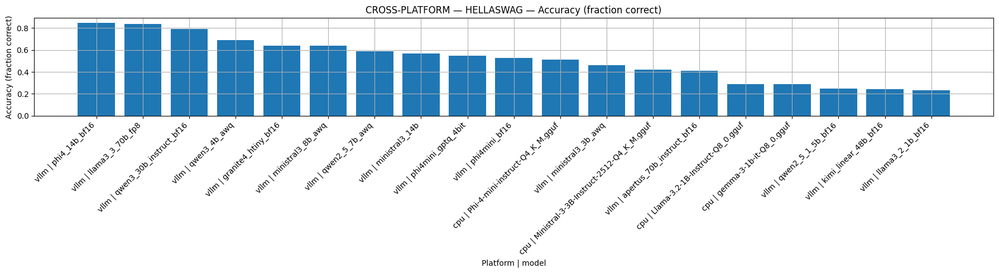

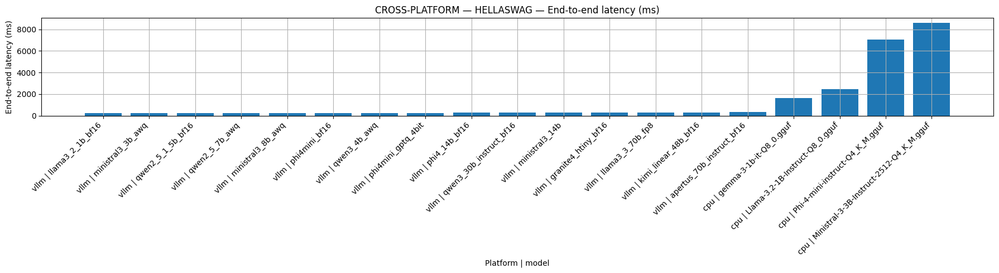

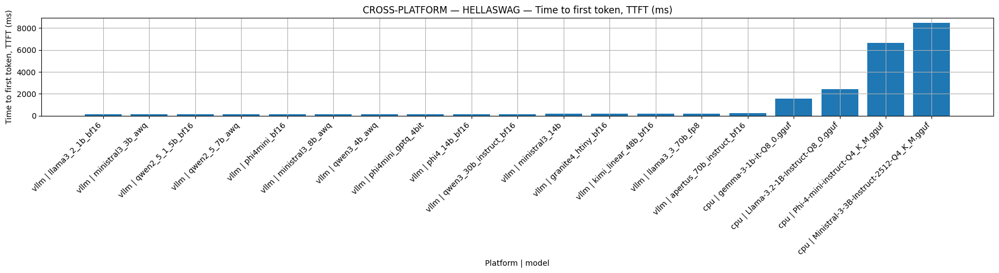

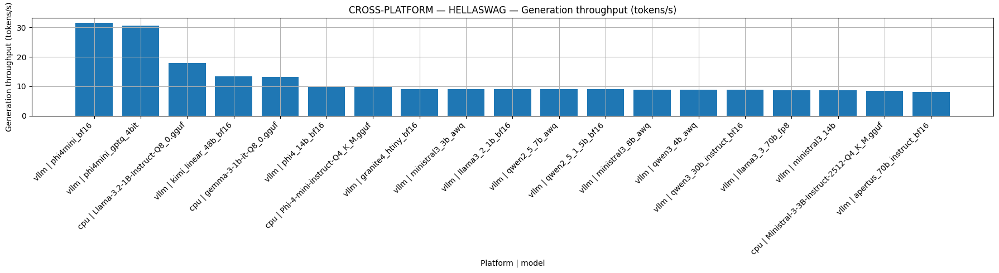

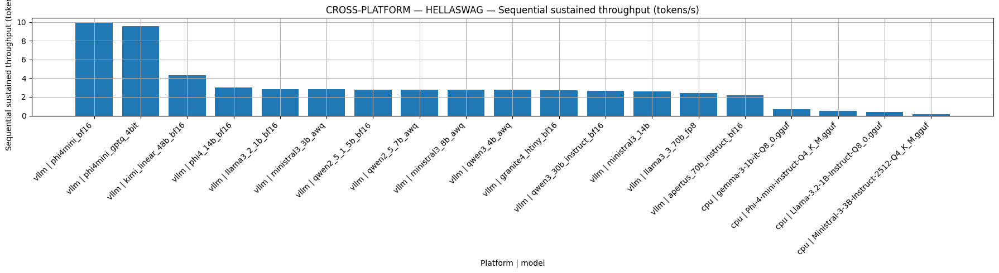

...

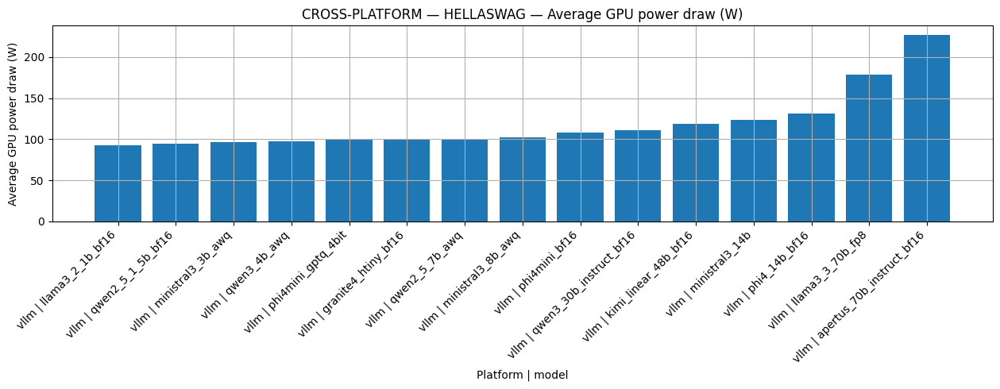

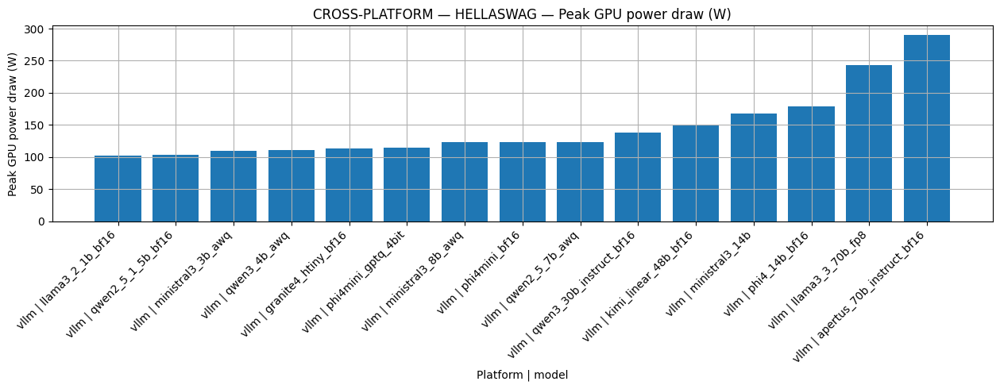

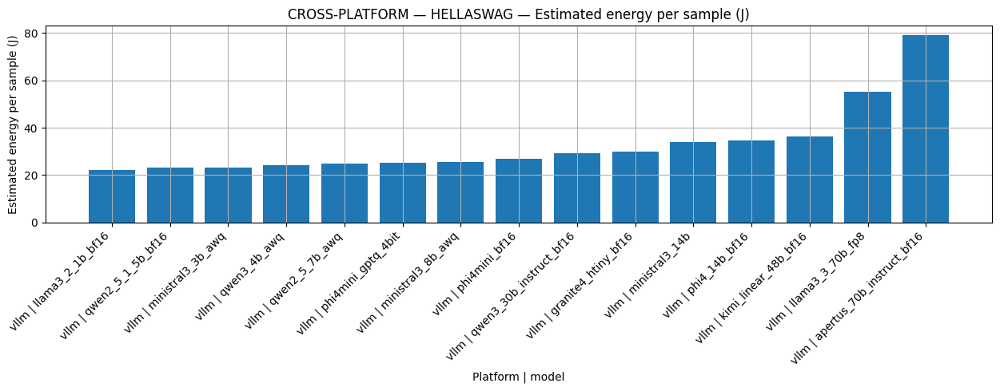

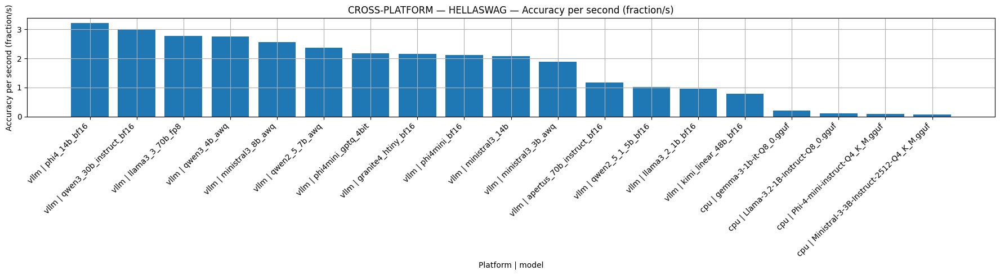

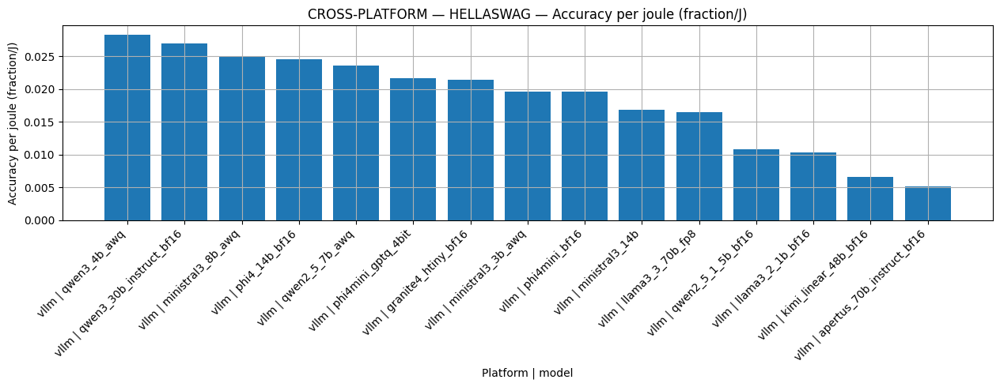

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


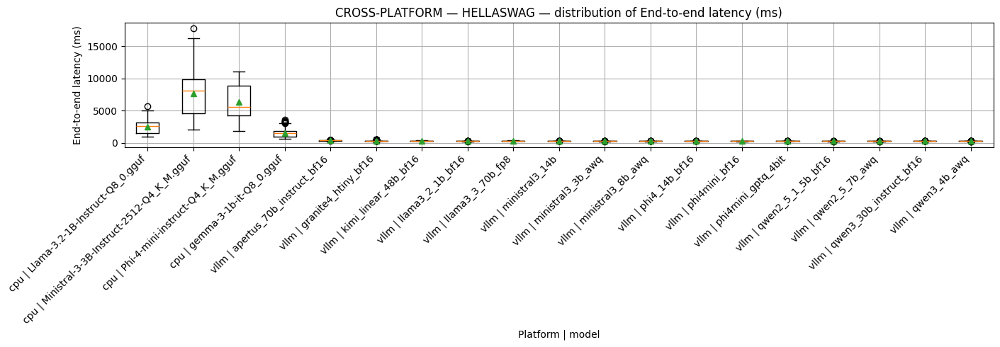

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


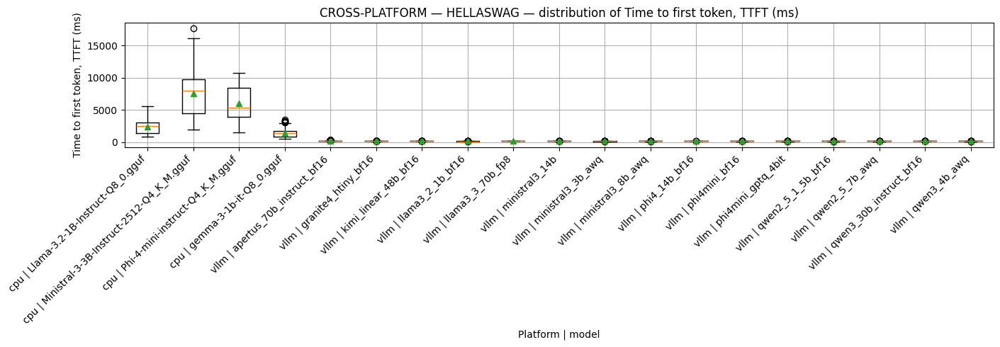

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


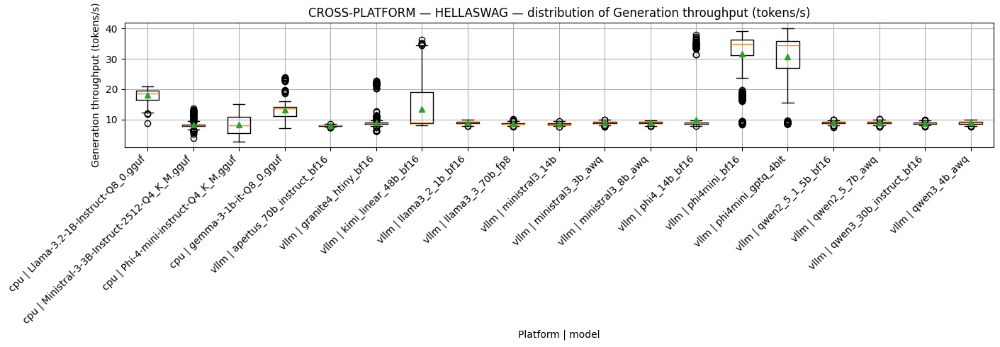

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


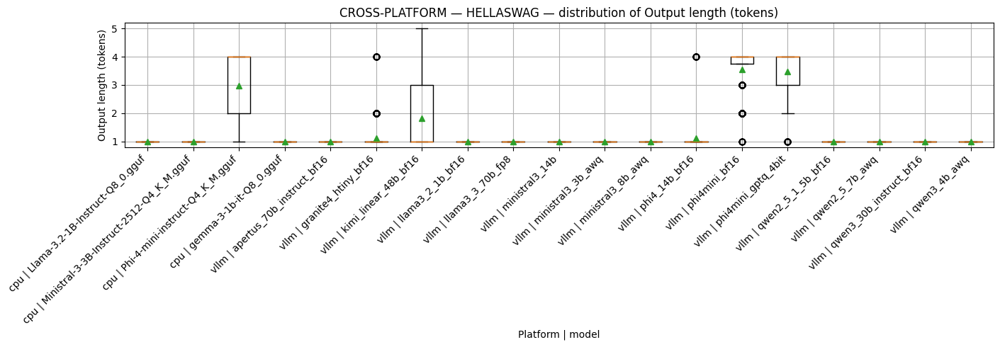

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


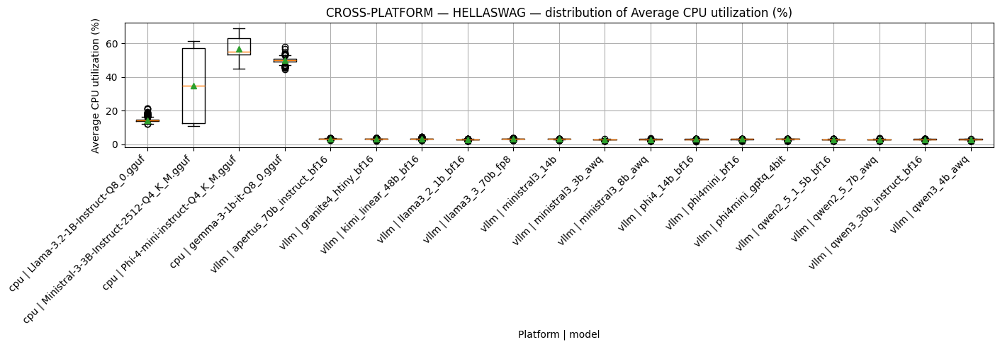

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


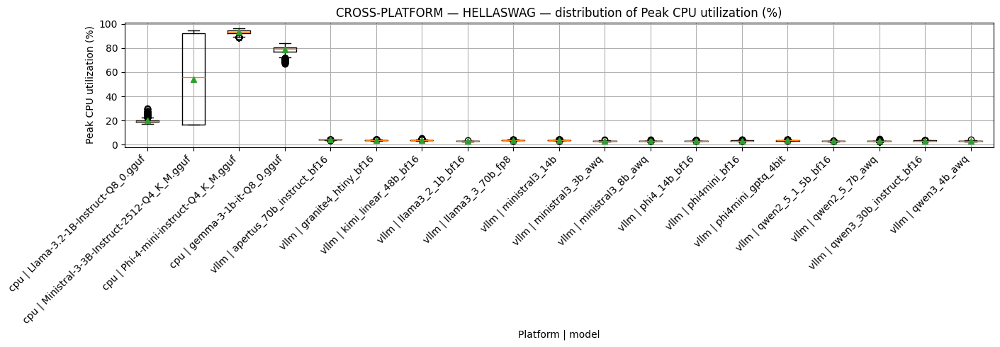

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


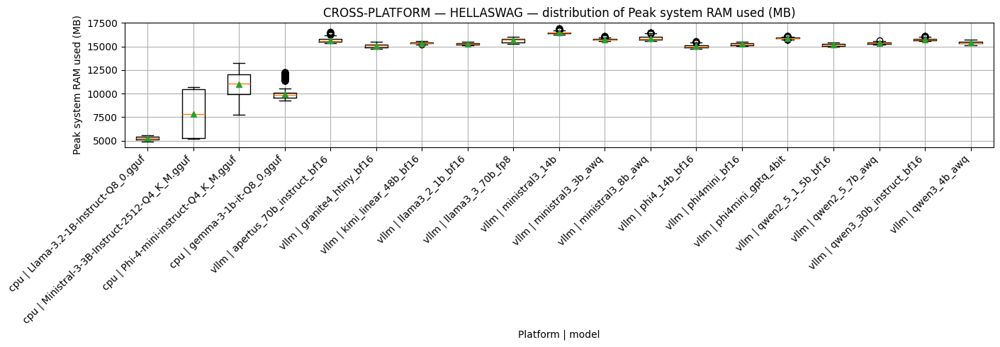

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


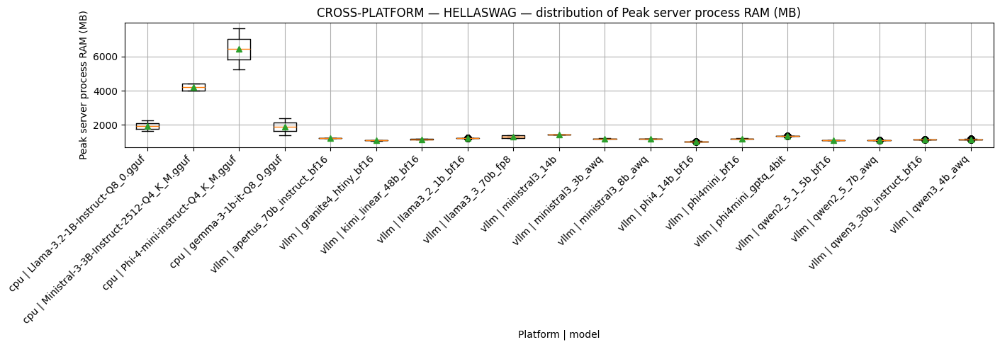

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


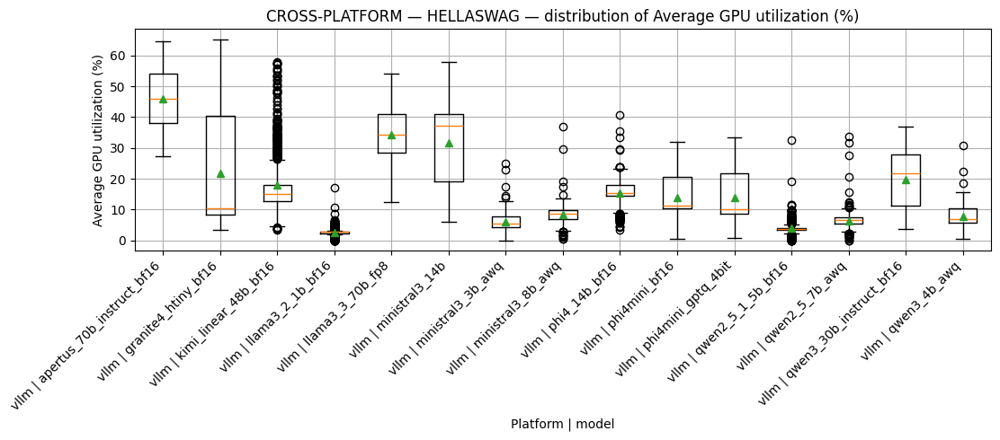

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


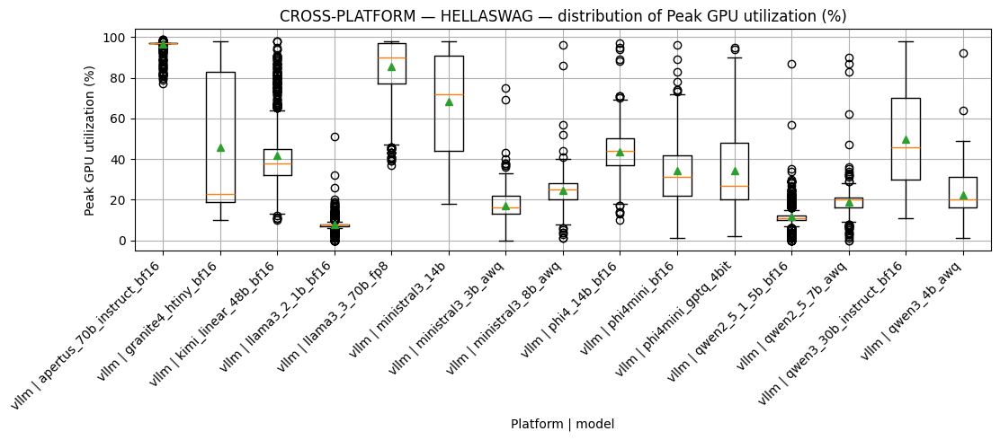

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


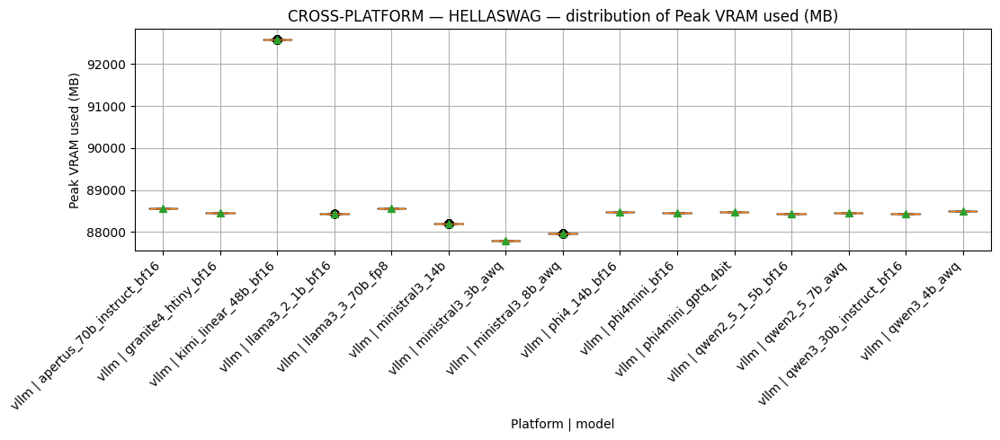

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


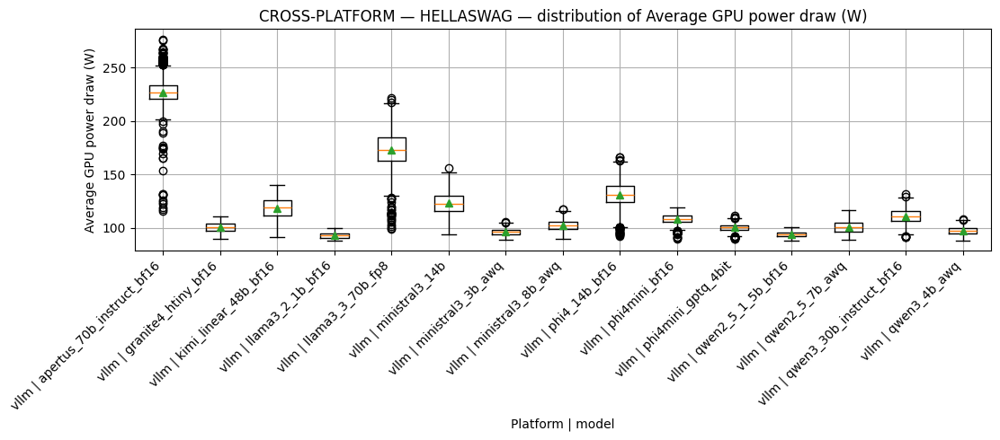

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


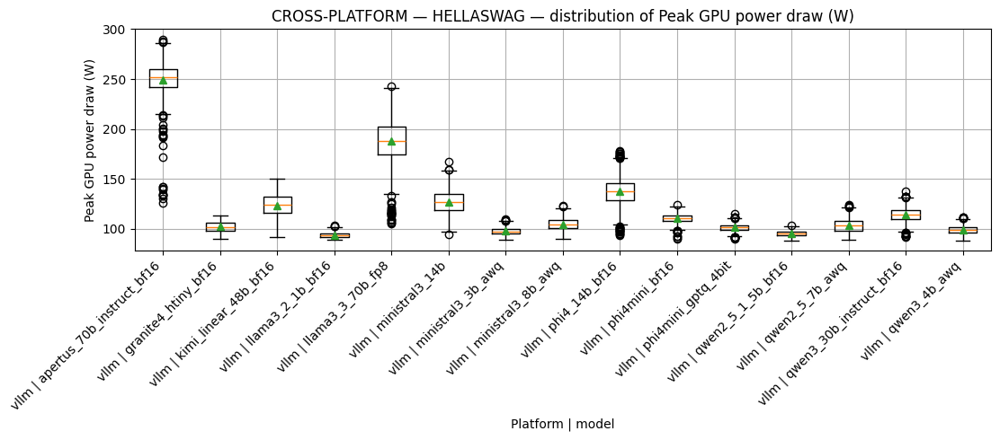

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


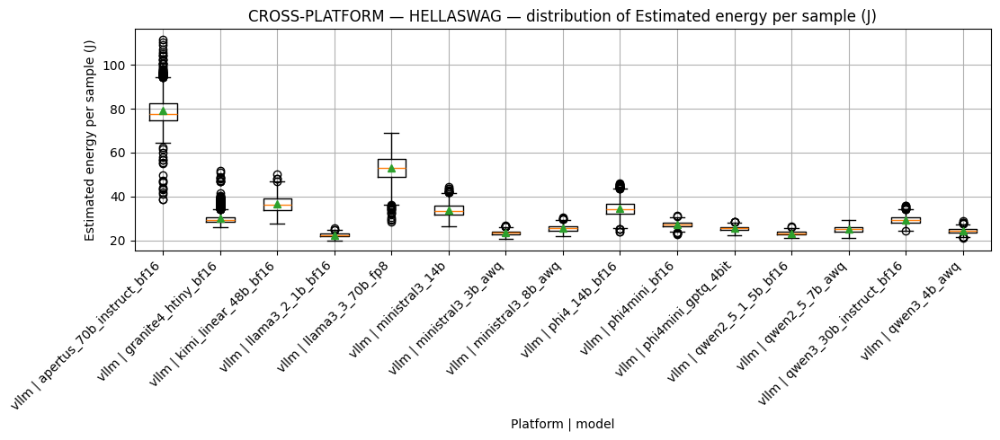

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


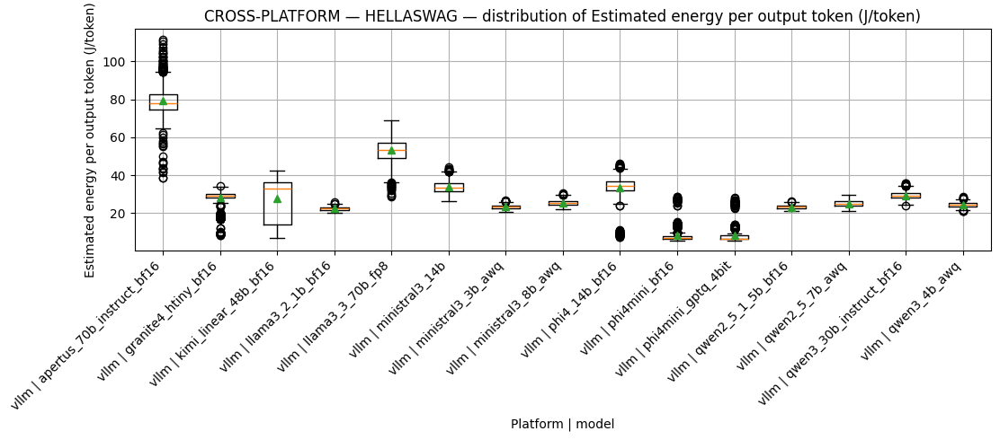

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


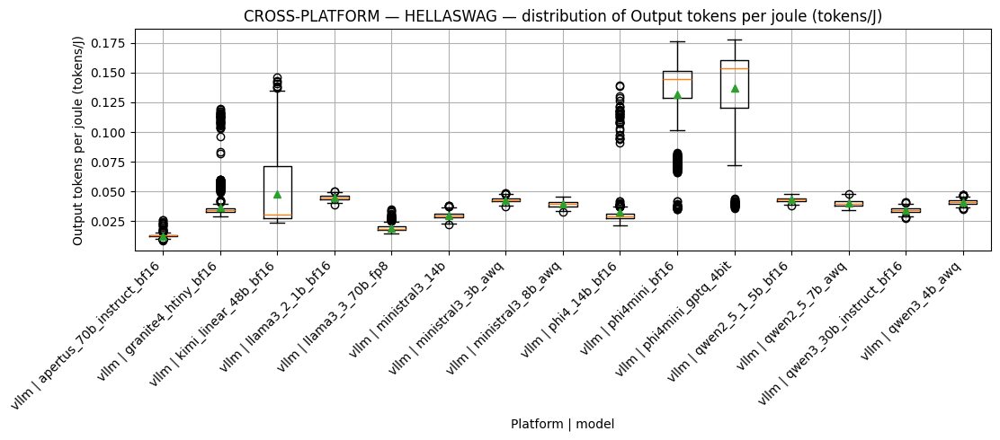

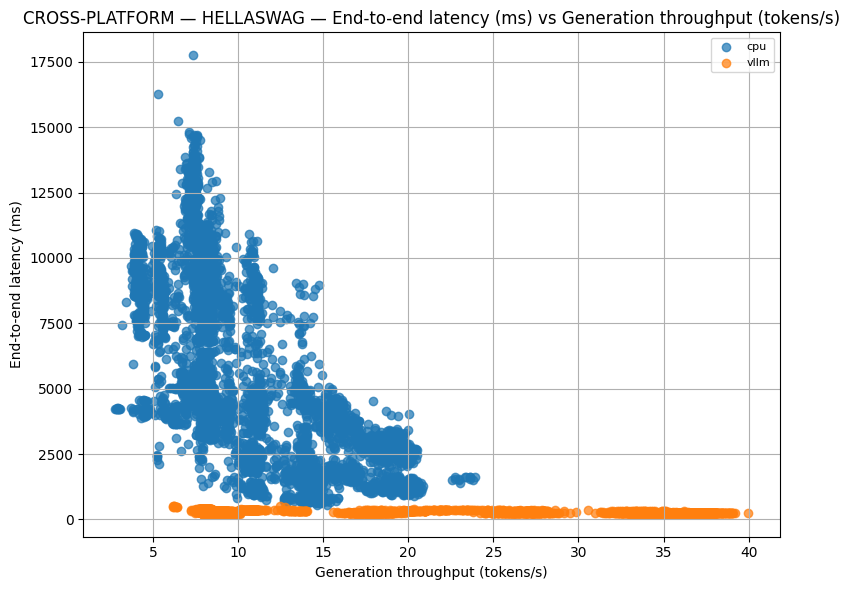

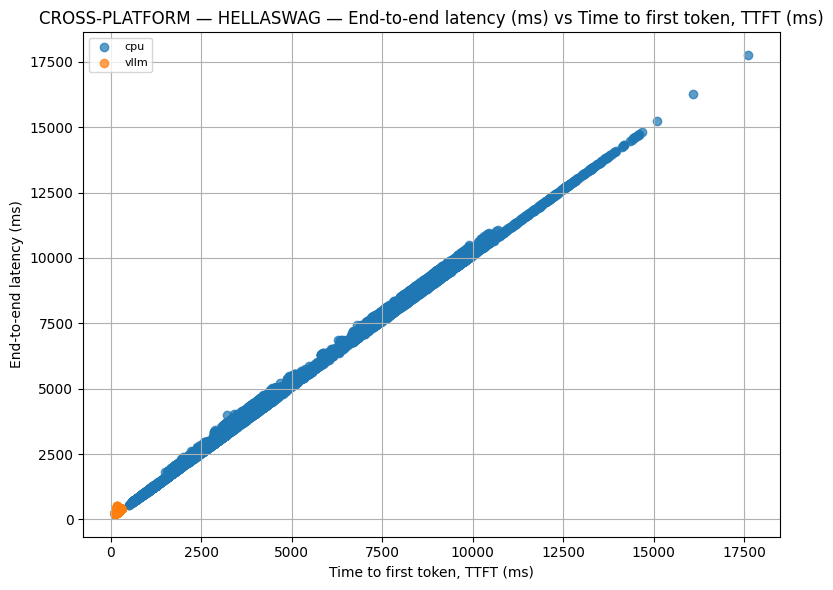

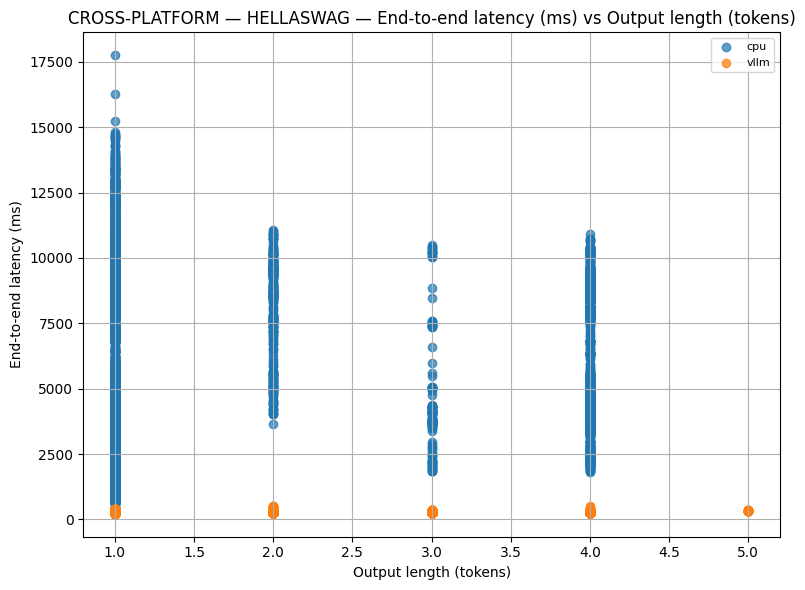

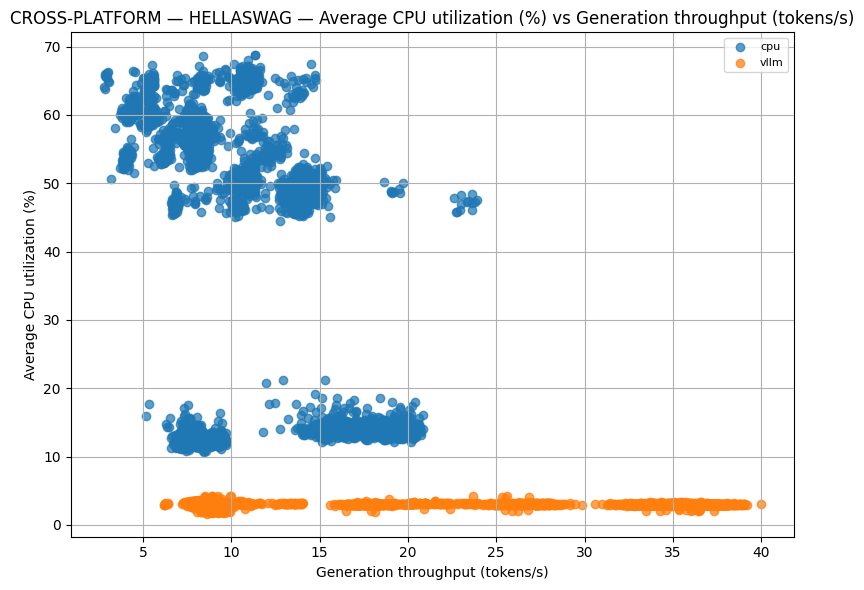

...

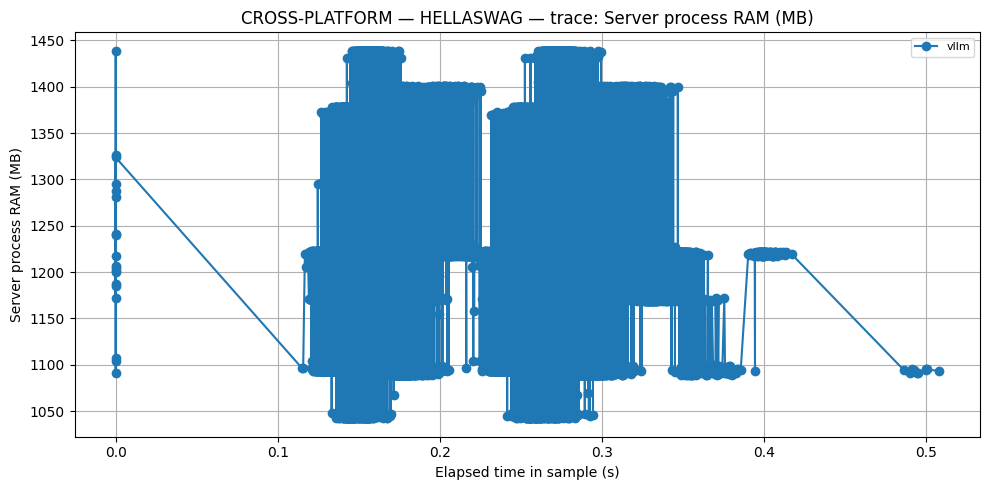

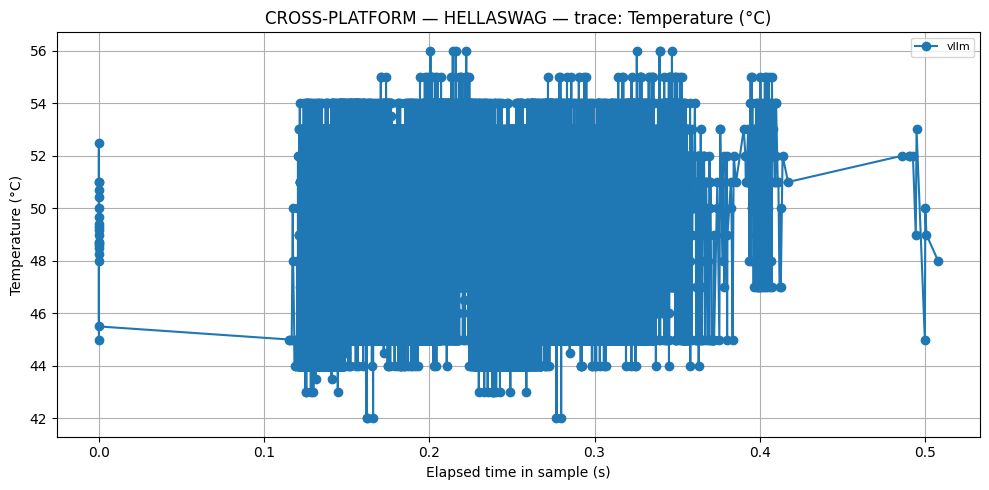

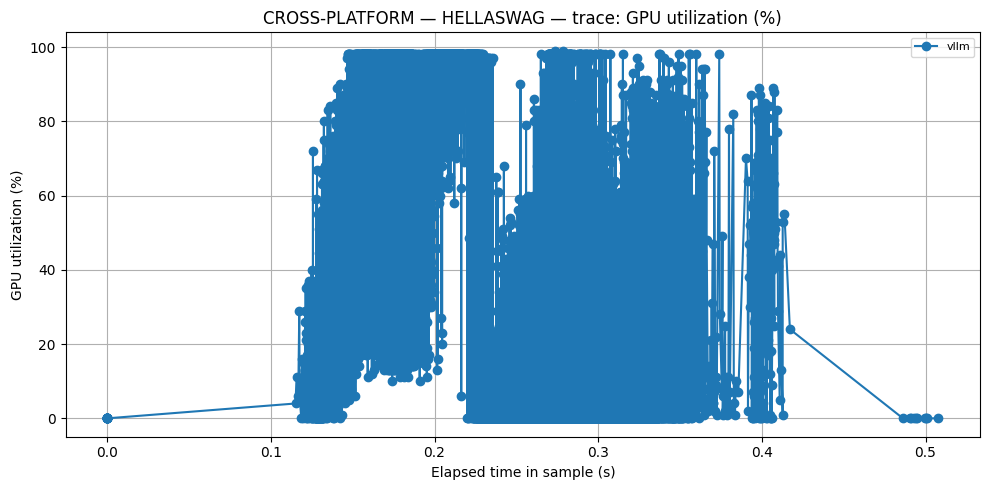

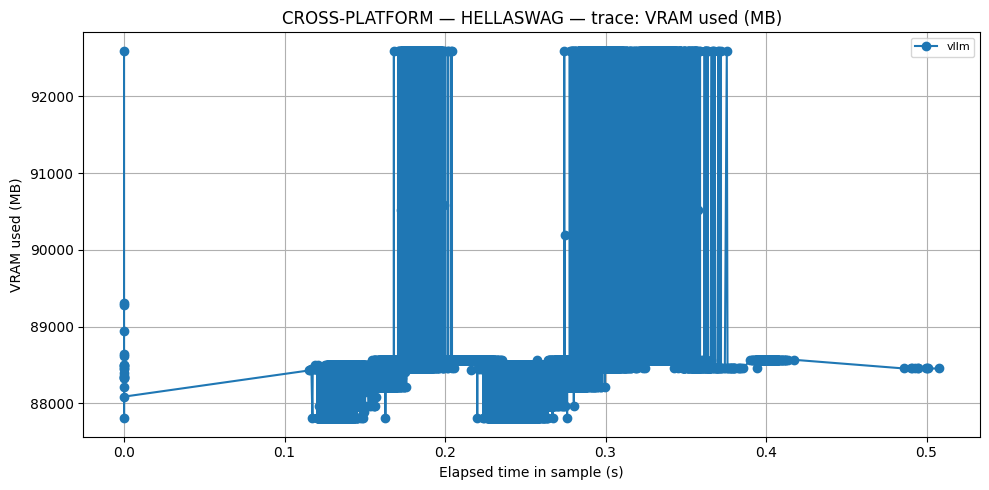

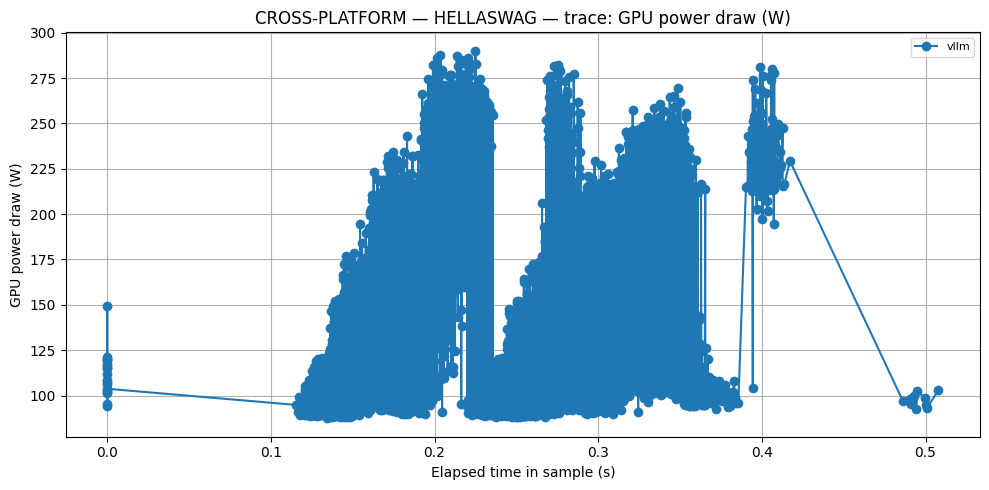


=== CROSS-PLATFORM / MMLU ===


,platform,model,accuracy,latency_ms,ttft_ms,tokens_per_sec,sustained_tokens_per_sec,samples_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,gpu_util_percent_avg,gpu_util_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,energy_j,accuracy_per_second,accuracy_per_joule
12,vllm,phi4_14b_bf16,0.820,261.19200,147.2386,11.40860,3.496800,2.689800,2.98230,4.000000,15283.800,1047.500000,14.91800,99.0,88487.0,130.75800,179.200,34.152944,3.139453,0.024010
17,vllm,qwen3_30b_instruct_bf16,0.816,265.07980,151.5658,8.82570,2.660500,2.660500,2.96790,4.100000,16073.320,1168.410000,17.13470,98.0,88447.0,108.32340,146.980,28.714345,3.078318,0.028418
8,vllm,llama3_3_70b_fp8,0.802,295.71540,180.5733,8.69800,2.469450,2.469450,3.16565,4.900000,15985.140,1315.025000,33.51600,99.5,88565.0,165.11710,230.415,48.845067,2.712537,0.016450
18,vllm,qwen3_4b_awq,0.710,247.43290,135.3355,10.18400,3.188200,2.796600,2.88530,3.900000,15741.890,1173.960000,7.40370,87.0,88503.0,97.07700,119.190,24.020044,2.869465,0.029559
9,vllm,ministral3_14b,0.700,274.18100,158.0240,8.61970,2.597300,2.597300,3.07200,4.600000,19753.030,1443.510000,27.07430,98.0,88211.0,121.51040,155.920,33.315843,2.553058,0.021011
16,vllm,qwen2_5_7b_awq,0.670,246.55900,135.1939,8.99660,2.803400,2.803400,2.83450,3.400000,15619.970,1107.210000,5.86830,81.0,88459.0,99.58780,134.450,24.554268,2.717402,0.027286
11,vllm,ministral3_8b_awq,0.660,244.42140,133.5740,9.03710,2.826800,2.826800,2.84550,3.500000,16149.640,1212.980000,8.43230,84.0,87963.0,101.23440,124.070,24.743854,2.700255,0.026673
10,vllm,ministral3_3b_awq,0.640,241.51010,130.3999,9.01710,2.838600,2.838600,2.82900,3.300000,16323.570,1212.080000,6.30330,87.0,87805.0,95.30970,110.020,23.018255,2.649993,0.027804
13,vllm,phi4mini_bf16,0.630,251.21270,138.1578,23.88660,7.478100,2.769700,2.94980,4.200000,15453.390,1214.650000,12.89870,96.0,88467.0,107.01680,128.980,26.883979,2.507835,0.023434
1,cpu,Ministral-3-3B-Instruct-2512-Q4_K_M.gguf,0.630,5702.32495,5580.9905,8.34790,0.176600,0.176600,34.58110,63.750000,8231.270,4606.150000,NaN,NaN,NaN,NaN,NaN,NaN,0.112330,NaN


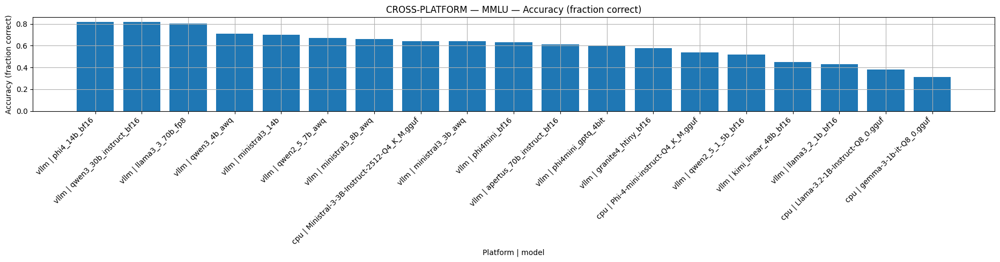

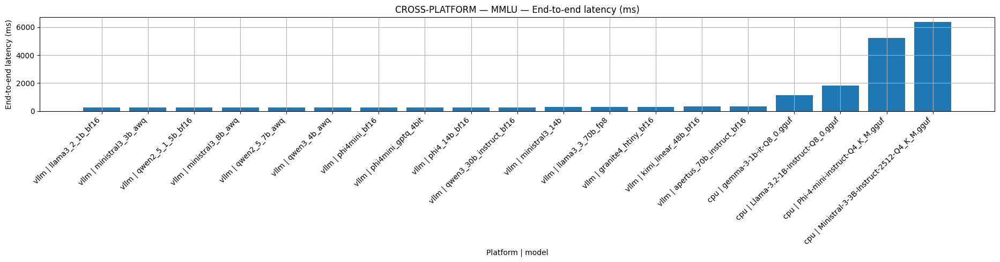

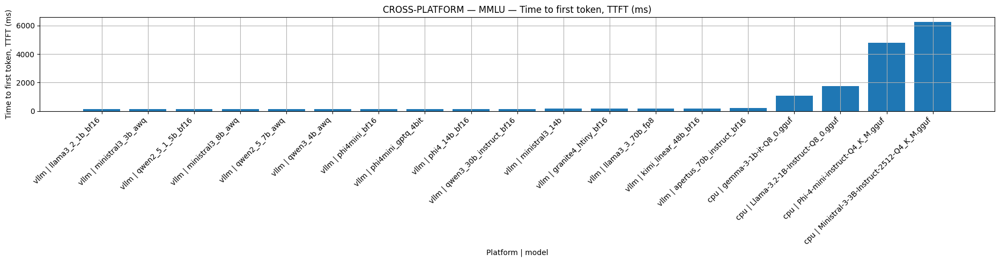

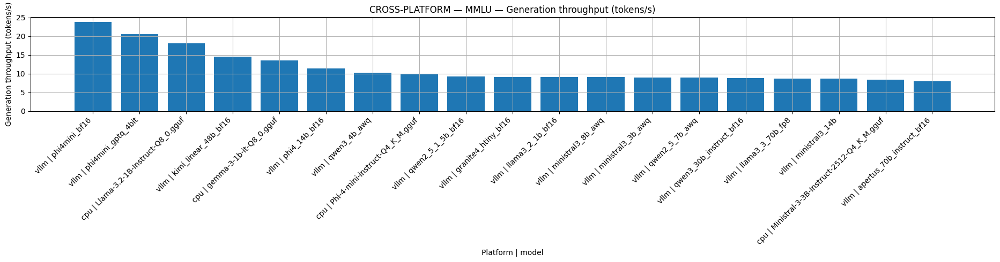

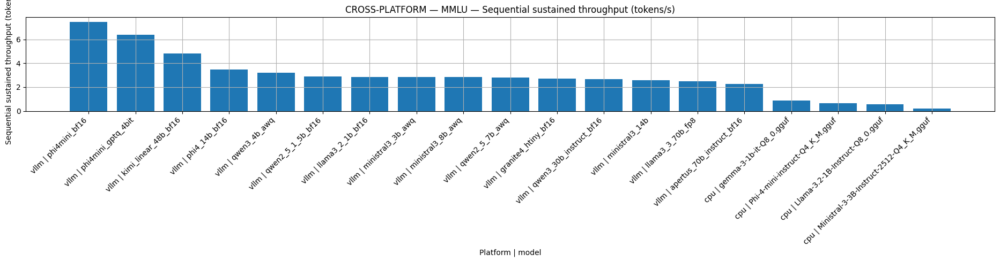

...

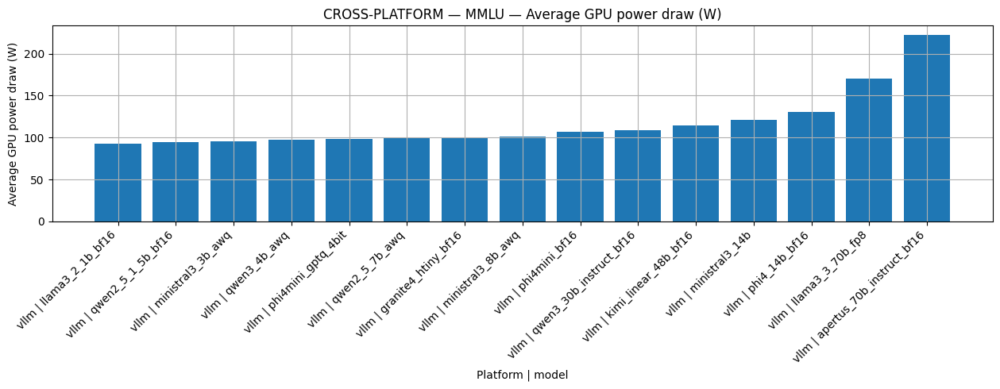

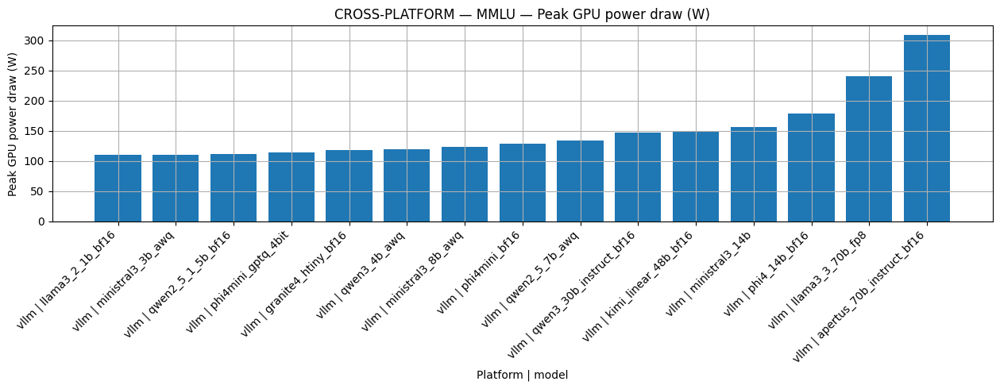

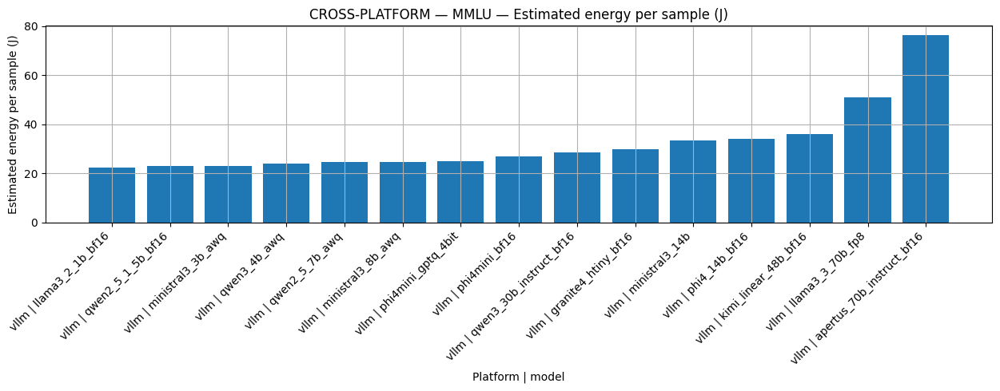

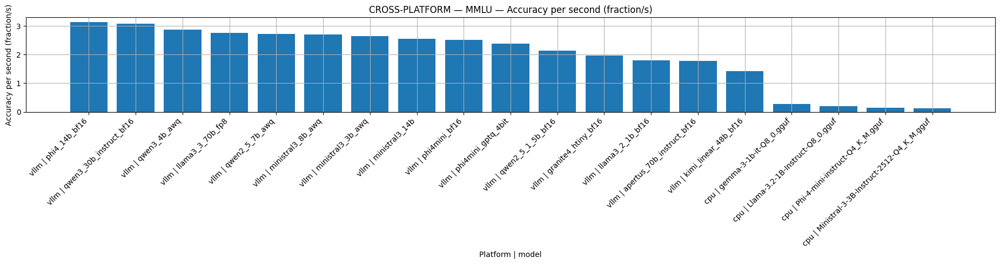

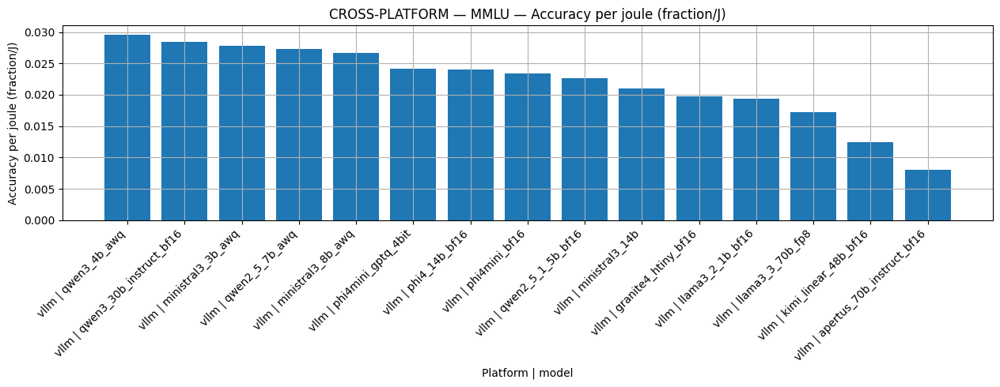

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


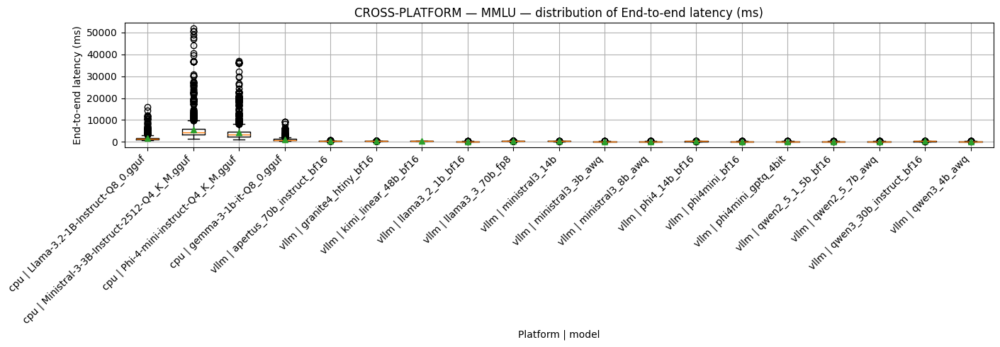

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


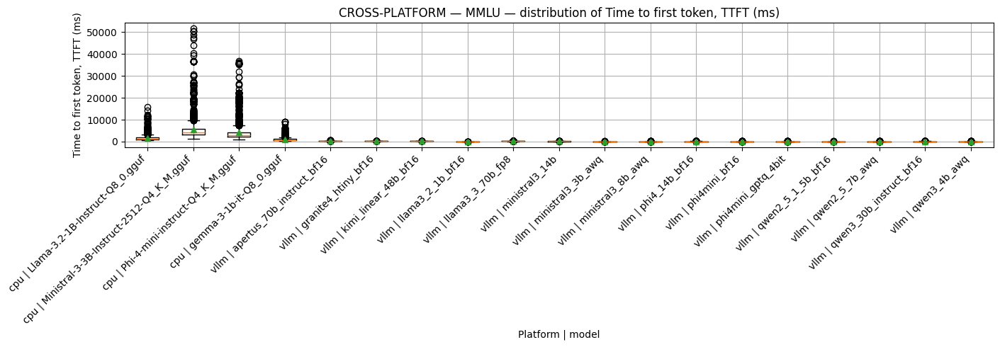

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


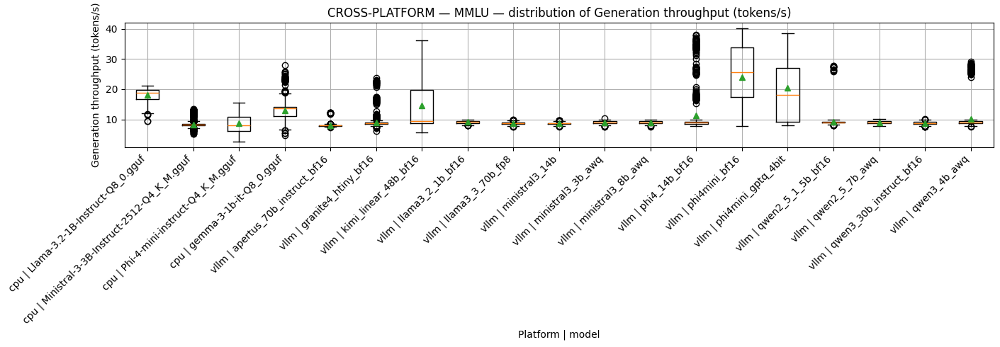

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


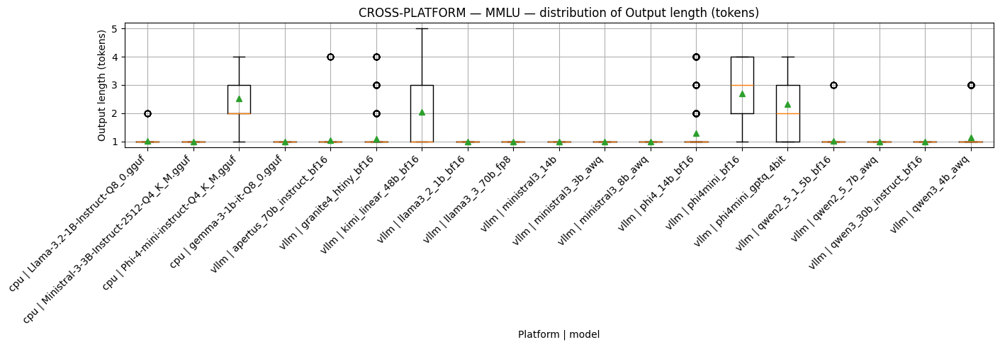

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


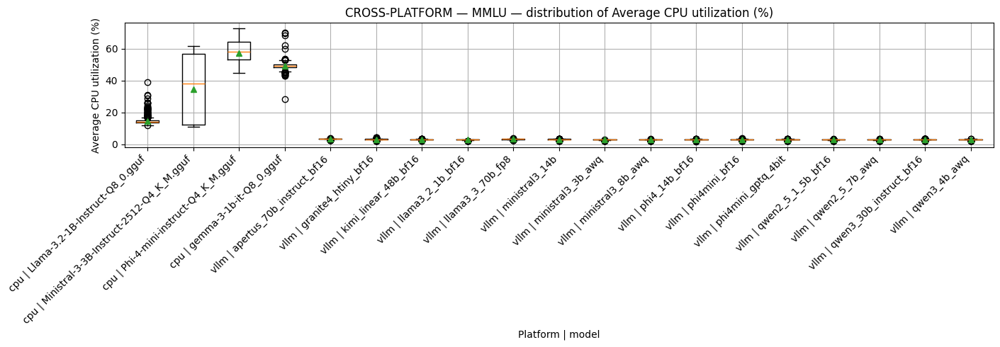

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


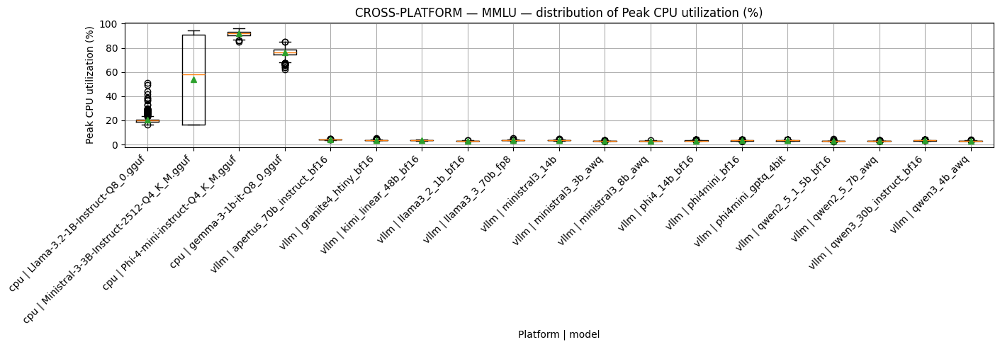

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


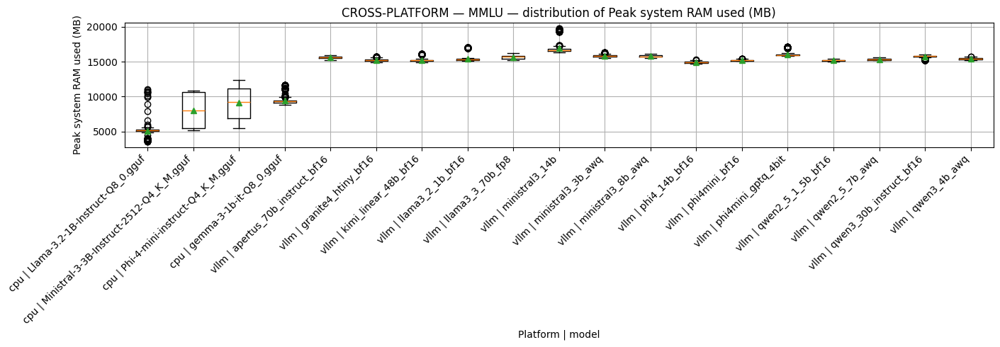

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


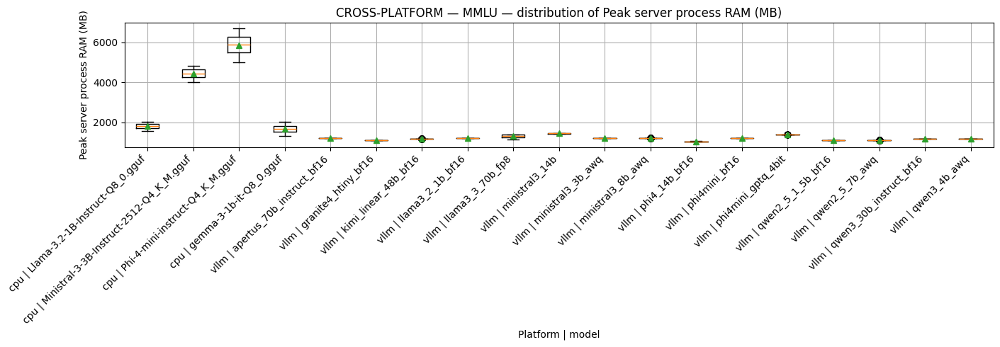

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


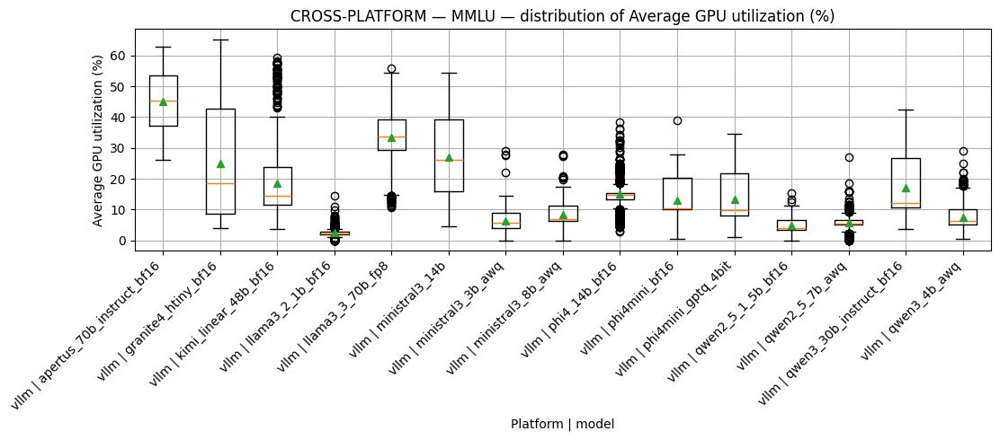

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


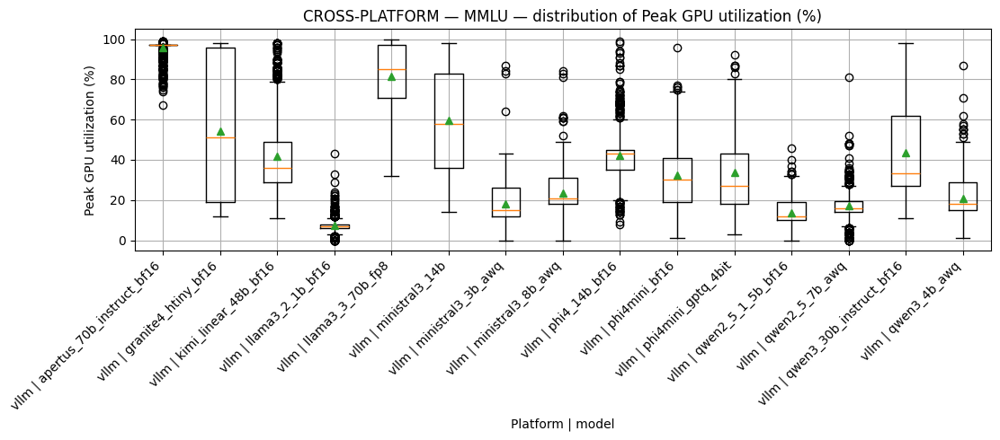

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


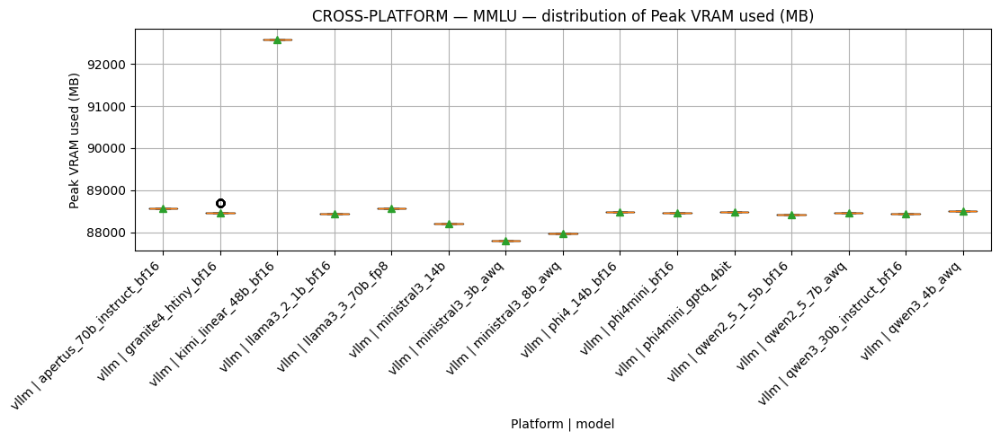

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


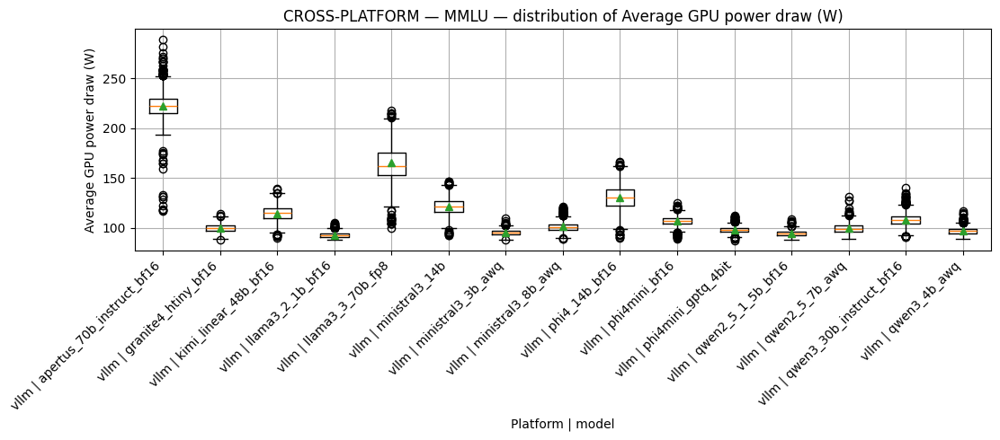

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


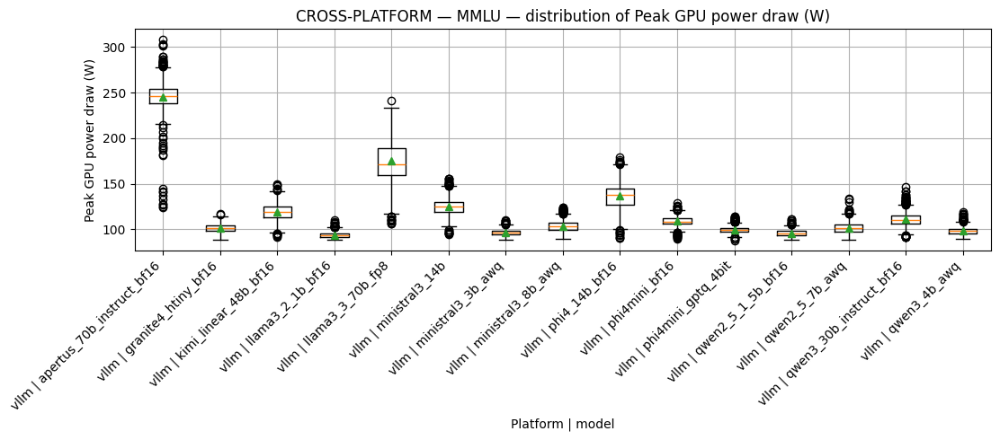

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


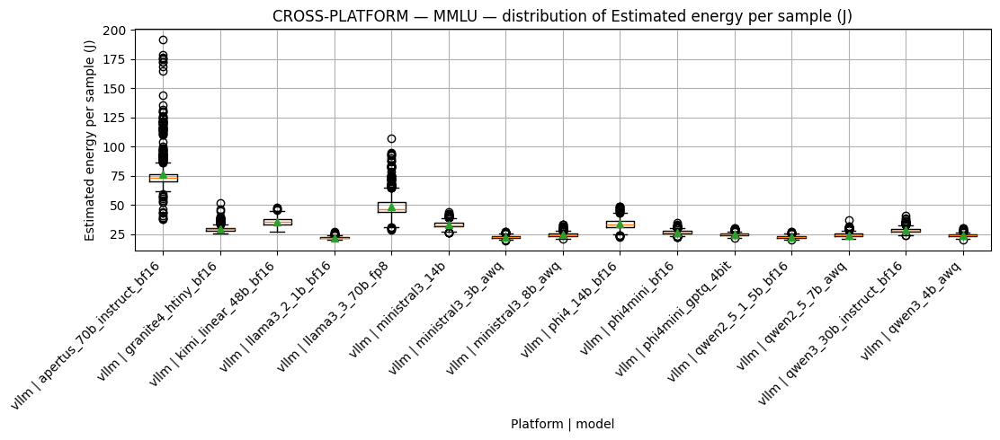

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


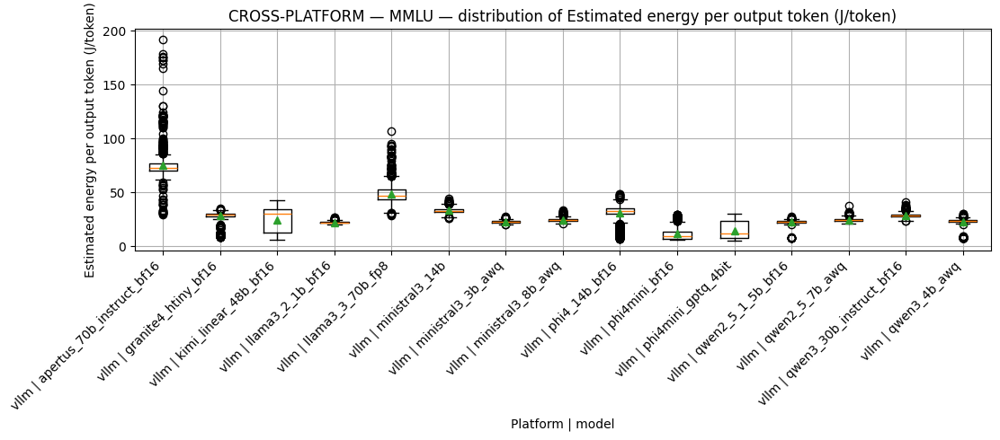

/tmp/ipykernel_2047414/2861991297.py:40: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vals, labels=labels, showmeans=True)


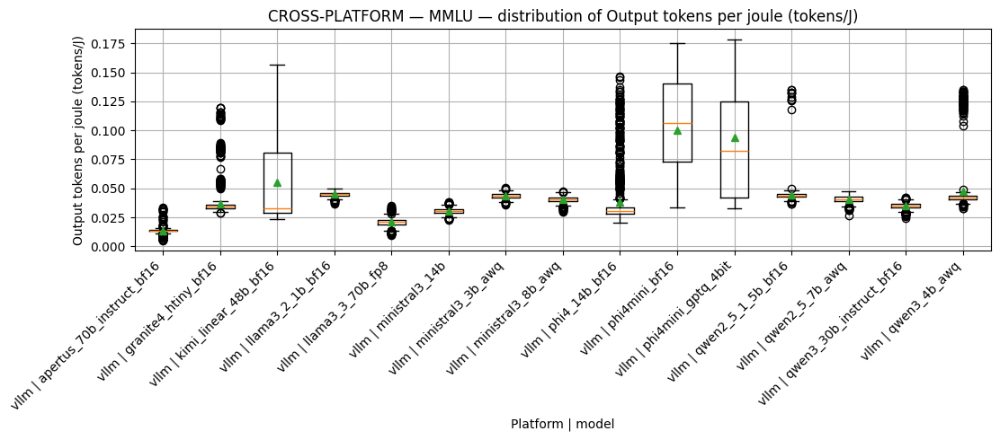

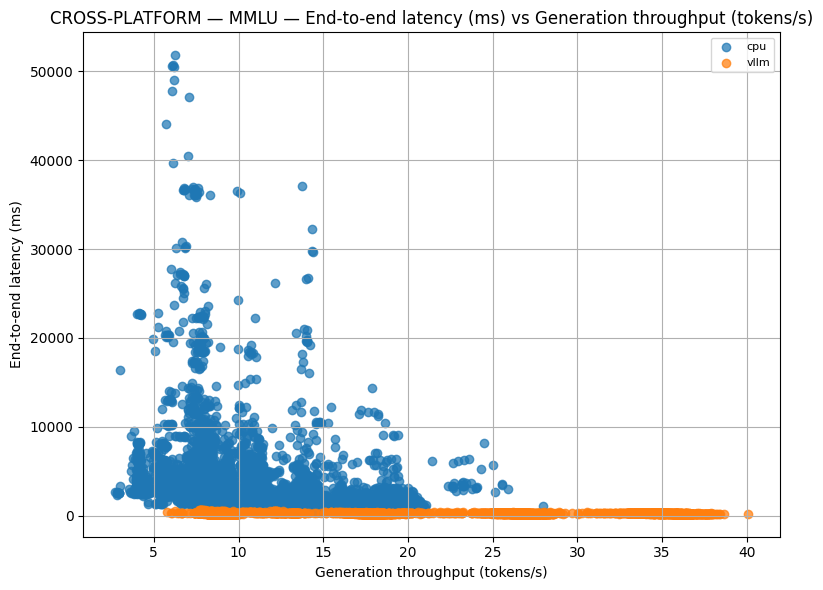

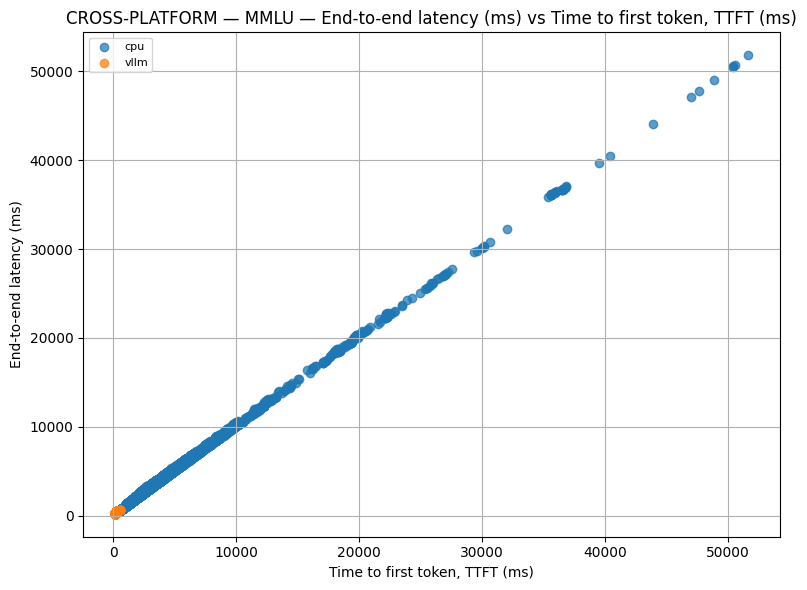

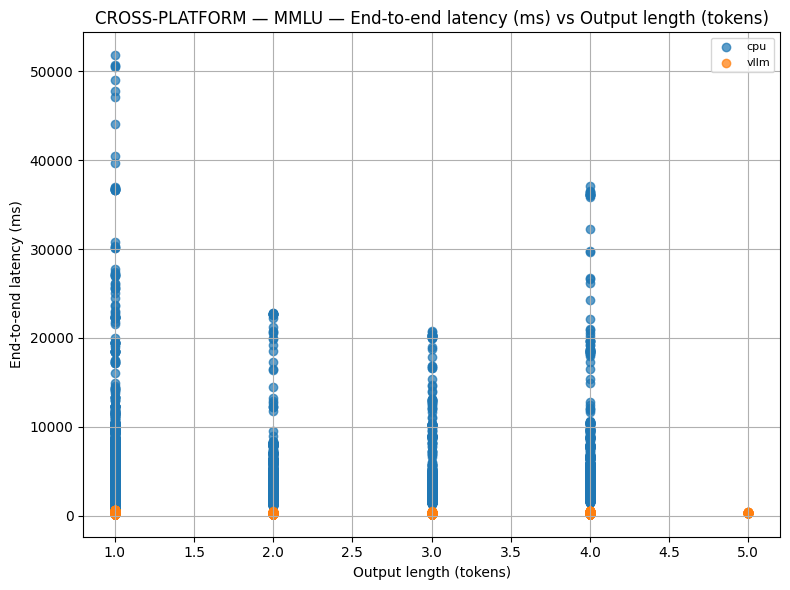

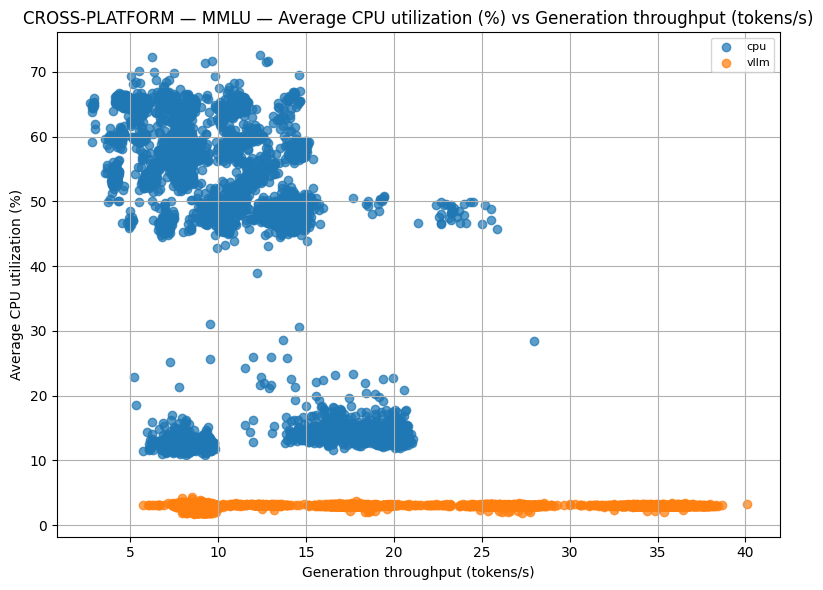

...

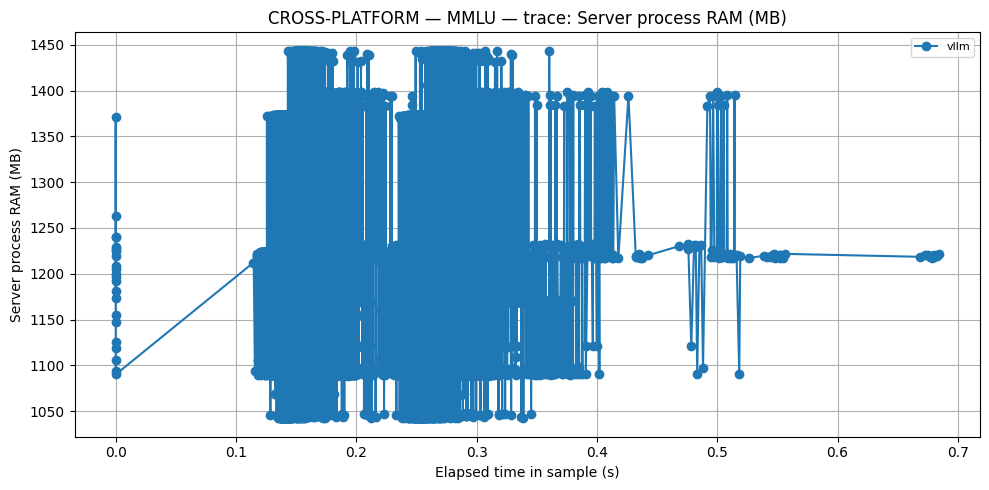

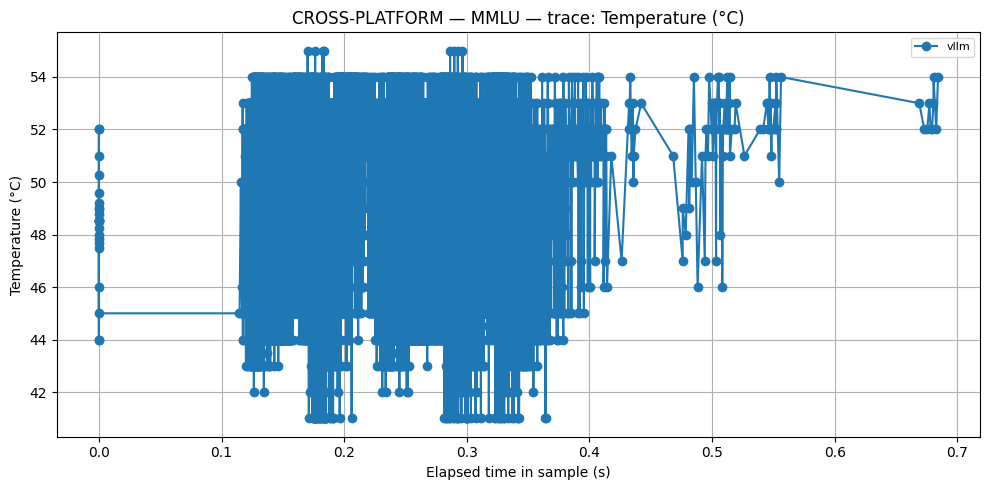

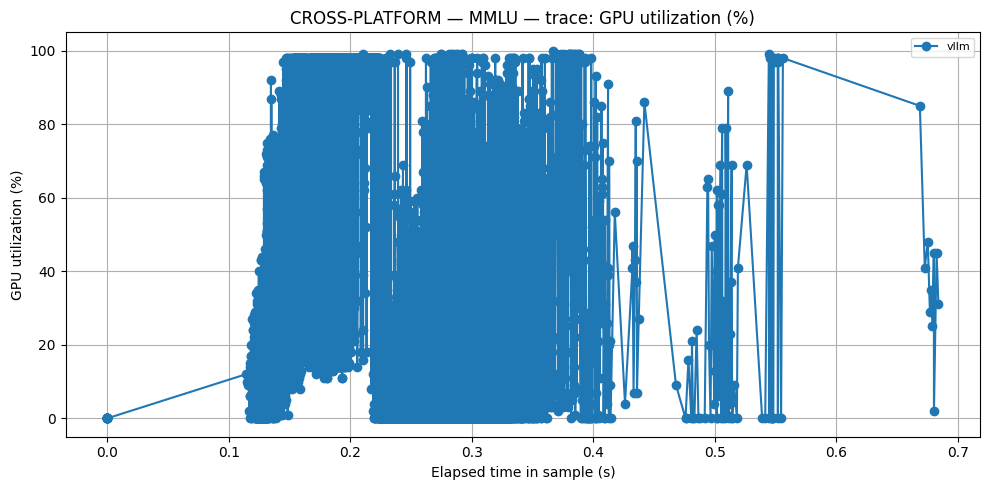

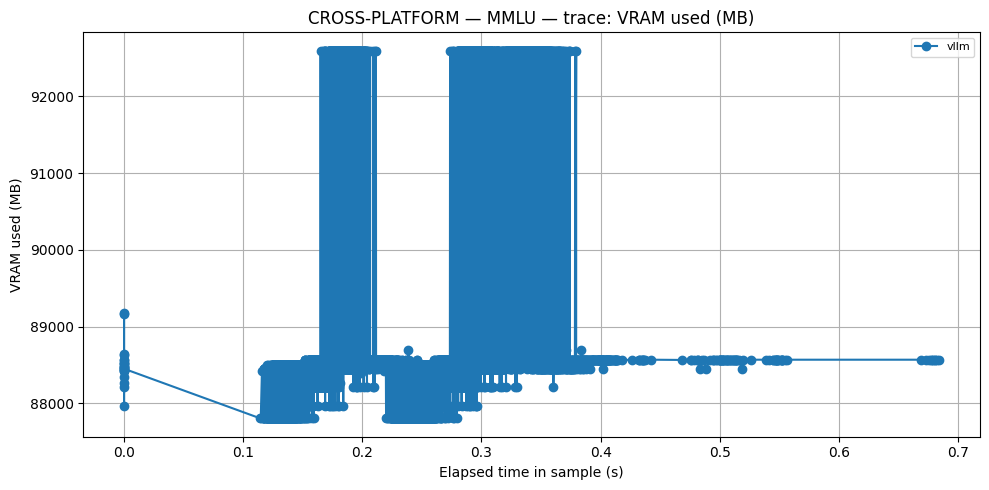

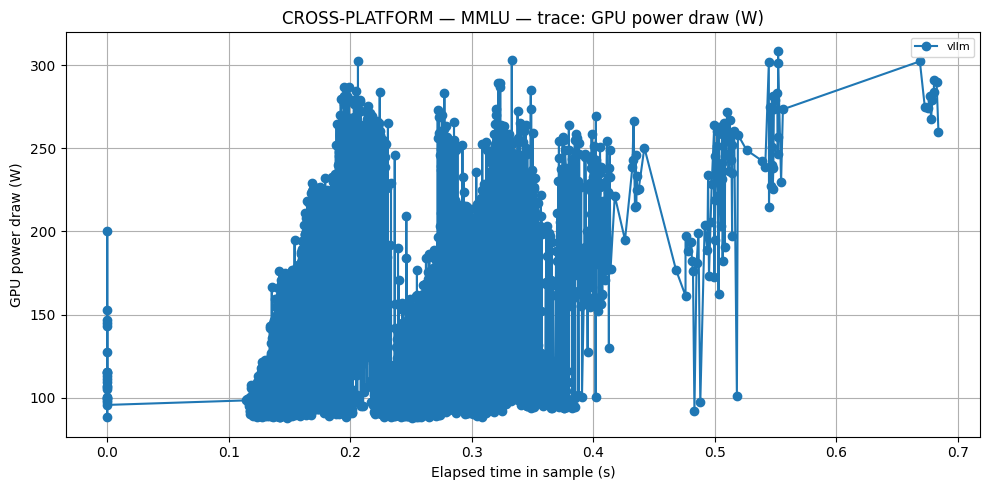

In [5]:
# Cross-platform comparison analysis
print("Platforms:", list(platform_data))
datasets = datasets_in(summary_all, samples_all, traces_all)
print("Datasets:", datasets)

available_summary_metrics = available_metrics(summary_all, SUMMARY_METRICS_COMMON)
available_sample_metrics = available_metrics(samples_all, SAMPLE_METRICS_COMMON)
available_trace_metrics = available_metrics(traces_all, TRACE_METRICS_COMMON)
print("Summary metrics:", available_summary_metrics)
print("Sample metrics:", available_sample_metrics)
print("Trace metrics:", available_trace_metrics)

for dataset in datasets:
    print(f"\n=== CROSS-PLATFORM / {dataset.upper()} ===")
    display(ranking_table(summary_all, dataset, SUMMARY_METRICS_COMMON, group_cols=("platform", "model")))

    # Cross-platform bars with platform | model labels.
    for metric in available_summary_metrics:
        if dataset == "dolly" and metric.startswith("accuracy"):
            continue
        bar_metric_by_model(summary_all, "cross-platform", dataset, metric, x_col="model_label", out_dir=FIGURES_DIR)

    # Cross-platform distributions with platform | model labels.
    for metric in available_sample_metrics:
        boxplot_metric_by_model(samples_all, "cross-platform", dataset, metric, x_col="model_label", out_dir=FIGURES_DIR)

    # Core frontiers / tradeoffs by platform.
    scatter_pairs = [
        ("tokens_per_sec", "latency_ms"),
        ("ttft_ms", "latency_ms"),
        ("output_tokens", "latency_ms"),
        ("tokens_per_sec", "cpu_percent_avg"),
        ("tokens_per_sec", "ram_used_mb_peak"),
        ("tokens_per_sec", "process_ram_mb_peak"),
        ("tokens_per_sec", "temp_c_avg"),
        ("tokens_per_sec", "gpu_util_percent_avg"),
        ("tokens_per_sec", "vram_used_mb_peak"),
        ("tokens_per_sec", "power_w_avg"),
        ("tokens_per_sec", "energy_j"),
        ("power_w_avg", "energy_j"),
    ]
    for x, y in scatter_pairs:
        scatter_metric_pair(samples_all, "cross-platform", dataset, x, y, group_col="platform", out_dir=FIGURES_DIR)

    # Accuracy vs cost/performance; only for scored datasets.
    if dataset in DATASETS_WITH_ACCURACY and metric_available(summary_all, "accuracy"):
        for x in ["latency_ms", "tokens_per_sec", "sustained_tokens_per_sec", "samples_per_sec", "cpu_percent_avg", "ram_used_mb_peak", "process_ram_mb_peak", "temp_c_avg", "gpu_util_percent_avg", "vram_used_mb_peak", "power_w_avg", "energy_j", "energy_per_token_j", "tokens_per_joule"]:
            scatter_metric_pair(summary_all, "cross-platform", dataset, x, "accuracy", group_col="platform", out_dir=FIGURES_DIR, annotate=True)
        for metric in ["accuracy_per_second", "accuracy_per_joule"]:
            if metric_available(summary_all, metric):
                bar_metric_by_model(summary_all, "cross-platform", dataset, metric, x_col="model_label", out_dir=FIGURES_DIR)

    # Cross-platform traces where fields are comparable.
    for metric in available_trace_metrics:
        trace_metric_plot(traces_all, "cross-platform", dataset, metric, group_col="platform", out_dir=FIGURES_DIR)

In [6]:
# Optional VS Code export helper. Run this cell after saving the notebook file.
from pathlib import Path
notebook_name = Path(globals().get("__vsc_ipynb_file__", "visualization_notebook.ipynb"))
print("VS Code export command:")
print(f"jupyter nbconvert --to html --execute {notebook_name}")

VS Code export command:
jupyter nbconvert --to html --execute /home/stephane/resource-efficiency-benchmark/notebooks/03_visualization_gpu_x_cpu_fixed.ipynb
